# IMF Country Report → AI Pipeline → Financial Stability Dashboard
**Student ID:** 24142011 &nbsp;|&nbsp; **Allocation:** Guatemala, 2025–2026
**Report used:** IMF Country Report No. 26/217 – *Guatemala: 2026 Article IV Consultation – Press Release and Staff Report* (August 2026)

My allocation was Guatemala for 2025–2026. There is an Article IV report for both years (No. 25/260 and No. 26/217), and the brief says to use the latest one, so I used the 2026 report.

**How to run it:** open in Google Colab and click *Runtime → Run all*. Nothing has to be uploaded and Google Drive is not used:
1. The PDF is downloaded automatically from my GitHub repository. I first tried to download it from the IMF website in code, but the IMF blocks requests from Colab (403 Forbidden), so I downloaded it once in my browser and put a copy in the repository.
2. My saved Gemini answers (`llm_cache.json`) are downloaded the same way, so the notebook gives the same results as my report even **without** an API key. A key is only needed for prompts that are not in the cache; it is read from Colab Secrets (`GEMINI_API_KEY`).

Everything the notebook produces is saved in `imf_outputs/` next to the notebook. I save every Gemini answer, every set of embeddings and the FAISS indexes to disk, so if the notebook is run a second time it does not call the API again and finishes in about a minute.

| Section | What I do there |
|---|---|
| 0. Setup | settings, Gemini connection, one helper function for all LLM calls |
| Task 1 | read and clean the PDF, split it into chunks, section and executive summaries, check them with a second model and with Python |
| Task 2 | theme counts, strengths and vulnerabilities, indicator JSON with fallbacks, time series, and checks on all of these |
| Task 3 | search over the report with local embeddings and FAISS, compare two embedding models, grounded answers with citation checks |
| Extension | Multi-Query RAG compared with normal single-question search |
| Task 4 | reshape the data with `pd.melt`, build the dashboard and an extra evaluation figure |

## 0. Setup
### 0.1 Libraries
I use `pypdf` to read the PDF, `tiktoken` to count tokens when making chunks, `google-genai` for Gemini, and `sentence-transformers` with `faiss-cpu` for the search part in Task 3.

I pinned the exact library versions I used. A newer pypdf could read the PDF slightly differently, which would change every prompt, so the saved answers in the cache would no longer match.

In [19]:
!pip install -q pypdf==6.21.4 tiktoken==0.14.0 google-genai==2.12.1 sentence-transformers==5.7.0 faiss-cpu==1.15.1 gdown

In [20]:
import os, re, sys, json, time, random, hashlib, unicodedata
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import tiktoken
from pypdf import PdfReader

pd.set_option("display.max_colwidth", 120)
print("Libraries loaded")

Libraries loaded


### 0.2 Configuration
I put every path, model name and setting in this one place, so nothing is typed in again further down and it is easy to change.

I use two groups of models. The **extractor** (full Flash models) writes the summaries, extracts the data and answers the RAG questions. The **judge** (Flash-Lite models) only checks the work. I kept them separate so the judge is never marking its own answers. Each group has a list of backup models because the free tier kept failing during my project with `429` (quota used up) and `503` (server busy) errors. If one model fails, the next one is tried, and I record which model produced each output.

The next cells make the notebook run on any account. I do not mount Google Drive, because that needs a sign-in pop-up for whoever runs it and failed when I tested with a second account ("credential propagation was unsuccessful"). Instead the PDF and the LLM cache are downloaded from my public GitHub repository (with a shared Drive link as backup). With the cache, the whole notebook re-uses my saved Gemini answers, so it gives the same results as my report and needs no API calls.

In [21]:
IN_COLAB = "google.colab" in sys.modules

# Everything is saved in the notebook's own folder (/content in Colab), NOT in Google Drive,
# so the notebook runs for any account without a Drive sign-in pop-up.
BASE_DIR   = "/content" if IN_COLAB else os.path.abspath(".")
PDF_PATH   = os.path.join(BASE_DIR, "guatemala_2026_article_iv.pdf")
OUT_DIR    = os.path.join(BASE_DIR, "imf_outputs")
CACHE_DIR  = os.path.join(OUT_DIR, "cache")
FIG_DIR    = os.path.join(OUT_DIR, "figures")

COUNTRY = "Guatemala"

# LLM roles: extractor (summaries, extraction, RAG answers) vs judge (evaluation only)
EXTRACT_MODELS = ["gemini-3.5-flash", "gemini-3-flash-preview", "gemini-3.6-flash",
                  "gemini-3.7-flash", "gemini-3.8-flash", "gemini-flash-latest"]
JUDGE_MODELS   = ["gemini-3.5-flash-lite", "gemini-3.1-flash-lite"]
TEMPERATURE    = 0.0          # deterministic as possible -> reproducible + cache-friendly
MIN_GAP_S      = 4            # pause between API calls (free-tier rate limits)

In [22]:
# Chunking (brief suggests 300-500 tokens with ~50-token overlap)
CHUNK_TOKENS   = 350          # leaves head-room under BGE's 512-token limit (see Task 3)
CHUNK_OVERLAP  = 50

# Retrieval
EMBED_MODELS = {"MiniLM": "sentence-transformers/all-MiniLM-L6-v2",   # baseline
                "BGE":    "BAAI/bge-small-en-v1.5"}                   # chosen model
QUERY_PREFIX = {"MiniLM": "", "BGE": "Represent this sentence for searching relevant passages: "}
TOP_K   = 5                   # baseline context size
MQ_K    = 8                   # broader context for Multi-Query RAG (extension)
RRF_K   = 60                  # standard Reciprocal Rank Fusion constant
SEED    = 42

FALLBACK = -1.0               # value for an indicator the report does not state
print("Config ready")

Config ready


In [23]:
# The PDF and my saved Gemini answers are downloaded automatically, so the notebook
# runs for someone without my Google Drive. Sources are tried in order:
#   1. a copy already in this session (re-runs)   2. my public GitHub repo   3. shared Drive link
GITHUB_RAW    = f"https://raw.githubusercontent.com/{GITHUB_REPO}/main"
PDF_FILE_ID   = "PASTE_PDF_FILE_ID"      # optional backup: Google Drive file IDs
CACHE_FILE_ID = "PASTE_CACHE_FILE_ID"

import requests

for d in (OUT_DIR, CACHE_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

def fetch(path, github_name, drive_id, check=None):
    """Download a file once. Returns True if the file is now on disk and passes `check`."""
    ok = lambda: os.path.exists(path) and (check is None or check(path))
    if ok():
        return True
    try:                                              # 1) GitHub
        r = requests.get(f"{GITHUB_RAW}/{github_name}", timeout=60)
        if r.status_code == 200:
            open(path, "wb").write(r.content)
    except Exception as e:
        print("GitHub download failed:", str(e)[:80])
    if not ok() and not drive_id.startswith("PASTE"):  # 2) Google Drive shared link
        try:
            import gdown
            gdown.download(id=drive_id, output=path, quiet=True)
        except Exception as e:
            print("Drive download failed:", str(e)[:80])
    if os.path.exists(path) and not ok():             # remove error pages saved by mistake
        os.remove(path)
    return ok()

In [24]:
is_pdf  = lambda p: open(p, "rb").read(4) == b"%PDF"
def is_json(p):
    try:
        return isinstance(json.load(open(p)), dict)
    except Exception:
        return False

cache_path = os.path.join(CACHE_DIR, "llm_cache.json")
fetch(PDF_PATH, "guatemala_2026_article_iv.pdf", PDF_FILE_ID, is_pdf)
if fetch(cache_path, "llm_cache.json", CACHE_FILE_ID, is_json):
    print("LLM cache found - saved Gemini answers will be re-used")
else:
    print("No LLM cache - answers will be generated with the API")

assert os.path.exists(PDF_PATH), (f"PDF not found. Put guatemala_2026_article_iv.pdf in the "
                                  f"GitHub repo {GITHUB_REPO} (or next to this notebook).")
print("PDF found:", PDF_PATH)
print("Outputs  :", OUT_DIR)

No LLM cache - answers will be generated with the API
PDF found: /content/guatemala_2026_article_iv.pdf
Outputs  : /content/imf_outputs


### 0.3 Gemini client and model availability
The API key is read from Colab Secrets, so it never appears in the notebook. I then check which of my models this key can actually use. I added this because `gemini-2.5-flash` gave me a `404` error when I started (it is no longer available to new users), and it is better to find that out at the start than halfway through a run.

If no API key is set, the notebook still runs: every answer is then read from the cache, and a call is only needed if a prompt is not in it.

In [25]:
from google import genai
from google.genai import types

# Key from an environment variable or Colab Secrets - never written in the notebook
API_KEY = os.environ.get("GEMINI_API_KEY")
if not API_KEY and IN_COLAB:
    try:
        from google.colab import userdata
        API_KEY = userdata.get("GEMINI_API_KEY")
    except Exception:
        API_KEY = None
if not API_KEY:
    print("No GEMINI_API_KEY - answers will come from the saved cache")
client = genai.Client(api_key=API_KEY) if API_KEY else None

if client:
    try:
        available = {m.name.split("/")[-1] for m in client.models.list()}
        EXTRACT_MODELS = [m for m in EXTRACT_MODELS if m in available]
        JUDGE_MODELS   = [m for m in JUDGE_MODELS if m in available]
    except Exception as e:
        print("Could not list models, using configured lists:", str(e)[:80])

assert EXTRACT_MODELS and JUDGE_MODELS, "No usable models for one of the roles"
assert not set(EXTRACT_MODELS) & set(JUDGE_MODELS), "Extractor and judge must differ"
print("Extractor models:", EXTRACT_MODELS)
print("Judge models    :", JUDGE_MODELS)

Extractor models: ['gemini-3.5-flash', 'gemini-3-flash-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'gemini-flash-latest']
Judge models    : ['gemini-3.5-flash-lite', 'gemini-3.1-flash-lite']


### 0.4 One helper for every LLM call
Every Gemini call in the notebook goes through the `llm()` function. It does four things:
- **Caching.** Each answer is saved to `cache/llm_cache.json`, using the prompt as the key. If the same prompt is sent again, the saved answer is used and no API call is made. This saved me a lot of quota when I had to re-run cells.
- **Fallback.** If a model says "not found", I stop using it. If it is busy or out of quota, the next model is tried, and after a full round it waits before trying again.
- **Recording.** Every answer is stored with the model that wrote it and how long it took.
- **Failing clearly.** If every model fails, it raises an error. An earlier version of my code quietly returned nothing and still printed "done", so I ended up with empty summaries without noticing.

In [26]:
LLM_CACHE_PATH = os.path.join(CACHE_DIR, "llm_cache.json")

def load_json(path, default):
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return default

def save_json(obj, path):
    # write to a temp file first, so an interrupted run never leaves a corrupt file
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=str)
    os.replace(tmp, path)

llm_cache = load_json(LLM_CACHE_PATH, {})
print(f"LLM cache: {len(llm_cache)} saved answers")

LLM cache: 0 saved answers


In [27]:
def _error_kind(e):
    m = str(e)
    if "429" in m or "RESOURCE_EXHAUSTED" in m: return "quota limit"
    if "503" in m or "UNAVAILABLE" in m or "overloaded" in m.lower(): return "server busy"
    if "404" in m or "NOT_FOUND" in m: return "model not available"
    return m[:60]

def _call_gemini(model, prompt, system, json_mode):
    cfg = types.GenerateContentConfig(
        temperature=TEMPERATURE, system_instruction=system,
        response_mime_type="application/json" if json_mode else "text/plain")
    t0 = time.time()
    r = client.models.generate_content(model=model, contents=prompt, config=cfg)
    if not r.text:
        raise ValueError("empty response")
    return r.text, round(time.time() - t0, 2)

In [28]:
_unavailable, _last_call = set(), [0.0]
CALL_STATS = Counter()            # answers served from cache vs fresh API calls in this run

def llm(prompt, role="extract", system=None, json_mode=False, rounds=3):
    # Cached Gemini call with model fallback. Returns {text, model, latency, cached}.
    key = hashlib.sha256(json.dumps([role, system, json_mode, prompt]).encode()).hexdigest()
    if key in llm_cache:
        CALL_STATS["from cache"] += 1
        return {**llm_cache[key], "cached": True}

    CALL_STATS["api calls"] += 1
    models = EXTRACT_MODELS if role == "extract" else JUDGE_MODELS
    for rnd in range(rounds):
        for m in [m for m in models if m not in _unavailable]:
            time.sleep(max(0, MIN_GAP_S - (time.time() - _last_call[0])))
            _last_call[0] = time.time()
            try:
                text, latency = _call_gemini(m, prompt, system, json_mode)
                llm_cache[key] = {"text": text, "model": m, "latency": latency, "role": role}
                save_json(llm_cache, LLM_CACHE_PATH)
                return {**llm_cache[key], "cached": False}
            except Exception as e:
                kind = _error_kind(e)
                print(f"  {m}: {kind}, trying next")
                if kind == "model not available":
                    _unavailable.add(m)
        if rnd < rounds - 1:
            print(f"  all {role} models busy - waiting {30 * (rnd + 1)}s")
            time.sleep(30 * (rnd + 1))
    raise RuntimeError(f"All {role} models failed. Completed calls are cached - re-run this cell later.")

In [29]:
def parse_json(text):
    # Parse model JSON robustly: strip ``` fences; if needed, cut out the outermost {...} or [...].
    text = re.sub(r"^```(?:json)?|```$", "", text.strip(), flags=re.M).strip()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        starts = [i for i in (text.find("{"), text.find("[")) if i != -1]
        if not starts:
            raise
        start = min(starts)
        end = text.rfind("}" if text[start] == "{" else "]")
        return json.loads(text[start:end + 1])

def llm_json(prompt, role="extract", system=None):
    # JSON-mode call; if the reply is not valid JSON, ask once for a repaired version.
    res = llm(prompt, role=role, system=system, json_mode=True)
    try:
        return parse_json(res["text"]), res
    except (json.JSONDecodeError, ValueError):
        print("  invalid JSON - asking the model to repair it")
        fix = llm("Return ONLY the valid JSON equivalent of this text, nothing else:\n\n" + res["text"],
                  role=role, json_mode=True)
        return parse_json(fix["text"]), fix

In [30]:
# smoke test: one tiny call per role (cached after the first run)
for role in ("extract", "judge"):
    r = llm("Reply with the single word: ready", role=role)
    print(f"{role:8s} -> {r['text'].strip()!r:10s} model={r['model']}  cached={r['cached']}")

extract  -> 'ready'    model=gemini-3.5-flash  cached=False
judge    -> 'ready'    model=gemini-3.5-flash-lite  cached=False


---
# Task 1 – PDF Processing Pipeline & Summarisation
### 1.1 Document ingestion
I read the PDF page by page with `pypdf`. The report year and report number are taken from the document text itself instead of being typed in, and I use the year later to decide which table years are projections.

In [31]:
reader = PdfReader(PDF_PATH)
pages = [p.extract_text() or "" for p in reader.pages]

front = " ".join(pages[:3])
REPORT_YEAR = int(re.search(r"(20\d\d) ARTICLE IV CONSULTATION", front).group(1))
REPORT_NO   = re.search(r"Country Report No\.\s*(\d+/\d+)", front).group(1)

print(f"Pages: {len(pages)} | raw characters: {sum(map(len, pages)):,}")
print(f"Report: IMF Country Report No. {REPORT_NO} | Article IV year: {REPORT_YEAR}")

Pages: 78 | raw characters: 193,545
Report: IMF Country Report No. 26/217 | Article IV year: 2026


### 1.2 Extraction & cleaning
I printed some raw pages first to see what needed cleaning, and wrote one rule for each problem:

| Problem in the raw text | What I did |
|---|---|
| "GUATEMALA" printed at the top of every page | removed lines that appear on at least 30% of pages, so the code finds headers by itself |
| page numbers, "INTERNATIONAL MONETARY FUND", copyright lines | removed with simple patterns |
| contents-page lines like `Fiscal Developments ______ 35` | removed lines with `___`. In my first version these lines made one chunk 1,553 tokens long for the embedding model |
| sentences broken over several lines | joined a line break when it is clearly in the middle of a sentence |
| words split by a hyphen at the end of a line | kept the hyphen. I checked all 25 cases in this PDF and every one was a real hyphenated word (*near-term*, *12-month*). My first version joined them and made words like "nearterm" |
| different dash and minus characters | changed them all to a normal `-` so numbers are read the same way everywhere |

In [32]:
def find_repeated_lines(pages, min_frac=0.3):
    counts = Counter()
    for p in pages:
        counts.update({line.strip() for line in p.splitlines() if line.strip()})
    return {line for line, c in counts.items() if c >= min_frac * len(pages)}

REPEATED = find_repeated_lines(pages)
DASHES = dict.fromkeys(map(ord, "‐‑‒−"), "-")   # hyphen variants + minus -> "-"
removed = Counter()                                                  # how many lines each rule removed
print("Detected running headers/footers:", REPEATED)

Detected running headers/footers: {'GUATEMALA'}


In [33]:
def drop_line(s):
    # Return the name of the cleaning rule that removes this line, or None to keep it.
    if not s:                                     return "blank"
    if s in REPEATED:                             return "header/footer"
    if re.fullmatch(r"-?\d{1,3}", s):             return "page number / chart axis value"
    if re.search(r"INTERNATIONAL MONETARY FUND|©\s*20\d\d", s): return "IMF banner"
    if re.search(r"_{3,}", s):                    return "TOC leader / separator"
    return None

def clean_page(text):
    text = unicodedata.normalize("NFKC", text).translate(DASHES)
    kept = []
    for line in text.splitlines():
        rule = drop_line(line.strip())
        if rule: removed[rule] += 1
        else:    kept.append(line.strip())
    t = "\n".join(kept)
    t = re.sub(r"(\w)-\n(\w)", r"\1-\2", t)                   # keep compound hyphens
    t = re.sub(r"(?<=[a-z0-9,;])\n(?=[a-z(])", " ", t)        # join lines broken mid-sentence
    t = re.sub(r"[ \t]+", " ", t)
    return t.strip()

In [34]:
clean_pages = [clean_page(p) for p in pages]
full_text = "\n\n".join(clean_pages)

raw_chars = sum(map(len, pages))
print(f"Cleaned characters: {len(full_text):,} ({100 - 100 * len(full_text) / raw_chars:.1f}% removed)")
print("Lines removed by rule:", dict(removed))
with open(os.path.join(OUT_DIR, "cleaned_text.txt"), "w") as f:
    f.write(full_text)

Cleaned characters: 185,643 (4.1% removed)
Lines removed by rule: {'blank': 17, 'IMF banner': 73, 'header/footer': 75, 'page number / chart axis value': 296, 'TOC leader / separator': 42}


In [35]:
# before / after on the Key Issues page
print("RAW:\n", pages[5][:600], "\n\nCLEAN:\n", clean_pages[5][:600])

RAW:
 GUATEMALA
STAFF REPORT FOR THE 2026 ARTICLE IV CONSULTATION
  KEY ISSUES
Context. Sound fundamentals—low and stable inflation, solid fiscal and external buffers,
and current account surpluses—put Guatemala in a strong position to face ongoing high
uncertainty. However, growth potential remains constrained by poor public
infrastructure, which dampens private investment. Large remittances, though supporting
consumption, complicate monetary policy and put pressure on competitiveness.
Outlook and risks. Growth is projected to dip to 3.8 percent this year before converging
to 4 percent in the mediu 

CLEAN:
 STAFF REPORT FOR THE 2026 ARTICLE IV CONSULTATION
KEY ISSUES
Context. Sound fundamentals—low and stable inflation, solid fiscal and external buffers, and current account surpluses—put Guatemala in a strong position to face ongoing high uncertainty. However, growth potential remains constrained by poor public infrastructure, which dampens private investment. Large remittances, thou

**Does cleaning change the meaning?** Cleaning is only allowed to delete whole lines and to change spaces and dash characters. The check below proves this for every page: once spaces and punctuation are removed, each cleaned page is exactly the same as the lines it kept. So no word or number in the kept text was changed. The next cell lists examples of what each rule removed, so this can be checked too. In my run the kept text was identical on all 78 pages, and 4.1% of the characters were removed (mostly 296 page numbers and chart axis values, 75 repeated headers and 42 contents lines).

*One thing I noticed:* when the PDF breaks a line right after a dash (`NPLs—` then `concentrated…` on the next line), the line break stays. It doesn't affect reading or search, but it caused a false "not found" in my first quote check (fixed in 2.5).

In [36]:
def alnum(s):
    return re.sub(r"[^0-9a-z]", "", unicodedata.normalize("NFKC", s).translate(DASHES).lower())

def kept_lines(page):
    t = unicodedata.normalize("NFKC", page).translate(DASHES)
    return "\n".join(l.strip() for l in t.splitlines() if not drop_line(l.strip()))

identical = [alnum(kept_lines(p)) == alnum(c) for p, c in zip(pages, clean_pages)]
assert all(identical), f"cleaning altered kept text on pages {[i + 1 for i, ok in enumerate(identical) if not ok]}"
print(f"Kept text unchanged on {sum(identical)}/{len(pages)} pages (only whole lines removed)")

Kept text unchanged on 78/78 pages (only whole lines removed)


In [37]:
removed_examples = defaultdict(list)
for p in pages:
    for line in unicodedata.normalize("NFKC", p).translate(DASHES).splitlines():
        rule = drop_line(line.strip())
        if rule and rule != "blank" and len(removed_examples[rule]) < 4:
            removed_examples[rule].append(line.strip()[:70])
for rule, ex in removed_examples.items():
    print(f"{rule:32s} e.g. {ex}")

IMF banner                       e.g. ['© 2026 International Monetary Fund', '2 INTERNATIONAL MONETARY FUND', 'INTERNATIONAL MONETARY FUND 3', '4 INTERNATIONAL MONETARY FUND']
header/footer                    e.g. ['GUATEMALA', 'GUATEMALA', 'GUATEMALA', 'GUATEMALA']
page number / chart axis value   e.g. ['2', '3', '4', '0']
TOC leader / separator           e.g. ['CONTEXT ______________________________________________________________', 'RECENT DEVELOPMENTS __________________________________________________', 'OUTLOOK AND RISKS ____________________________________________________', 'POLICY DISCUSSIONS ___________________________________________________']


### 1.3 Token-aware, sentence-aware chunking
My first version cut the text every 400 tokens, so chunks often started in the middle of a word. Now I split each page into sentences (or table rows, since table rows have no full stop) and add them to a chunk until the next one would take it over 350 tokens. That way a chunk always ends at the end of a sentence or row.

For the overlap, the next chunk starts with the last full sentences of the previous one, up to 50 tokens. Because the overlap is made of whole sentences, a fact that falls on a boundary is complete in at least one chunk. With the overlap included a chunk can be up to about 400 tokens, which is inside the brief's 300–500 range. I chose 350 rather than 400 new tokens because the embedding model counts tokens differently from `tiktoken`, and this keeps every chunk under its 512-token limit (checked in Task 3).

In [38]:
enc = tiktoken.get_encoding("cl100k_base")
def n_tokens(s): return len(enc.encode(s))

SENT_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9(\"'])")

def page_units(page_no, text):
    # Split one page into sentence / table-row units: (page, paragraph_id, text, tokens).
    units = []
    for para_id, para in enumerate(text.split("\n")):
        for s in SENT_SPLIT.split(para.strip()):
            if s.strip():
                units.append((page_no, para_id, s.strip(), n_tokens(s)))
    return units

In [39]:
HARD_SPLITS = [0]

def hard_split(unit, max_tokens):
    # Rare: a single unit longer than a chunk (e.g. a run-on table) is cut by tokens.
    HARD_SPLITS[0] += 1
    page, para, text, _ = unit
    toks = enc.encode(text)
    return [(page, para, enc.decode(toks[i:i + max_tokens]), len(toks[i:i + max_tokens]))
            for i in range(0, len(toks), max_tokens)]

def join_units(units):
    out = units[0][2]
    for prev, u in zip(units, units[1:]):
        same_para = (u[0], u[1]) == (prev[0], prev[1])
        out += (" " if same_para else "\n") + u[2]
    return out

In [40]:
def chunk_document(pages, max_tokens=CHUNK_TOKENS, overlap=CHUNK_OVERLAP):
    units = [u for i, p in enumerate(pages, 1) for u in page_units(i, p)]
    units = [s for u in units for s in (hard_split(u, max_tokens) if u[3] > max_tokens else [u])]
    chunks, cur = [], []
    for u in units:
        if cur and sum(x[3] for x in cur) + u[3] > max_tokens:
            chunks.append(cur)
            carry = []                                   # trailing whole sentences as overlap
            for x in reversed(cur):
                if sum(c[3] for c in carry) + x[3] > overlap: break
                carry.insert(0, x)
            cur = carry
        cur.append(u)
    chunks.append(cur)
    return [{"chunk_id": i, "page": c[0][0], "page_end": c[-1][0],
             "n_tokens": n_tokens(join_units(c)), "text": join_units(c)} for i, c in enumerate(chunks)]

In [41]:
chunks = chunk_document(clean_pages)
sizes = [c["n_tokens"] for c in chunks]

assert max(sizes) <= CHUNK_TOKENS + CHUNK_OVERLAP + 10, "chunk larger than budget + overlap"
print(f"Chunks: {len(chunks)} | tokens min/median/max: {min(sizes)}/{int(np.median(sizes))}/{max(sizes)} "
      f"(budget {CHUNK_TOKENS} + overlap {CHUNK_OVERLAP})")
print(f"Every chunk ends at a sentence or table-row boundary; units that had to be cut by tokens: {HARD_SPLITS[0]}")
punct = np.mean([bool(re.search(r"[.!?]\s*$", c["text"])) for c in chunks])
print(f"Chunks ending with sentence punctuation: {100 * punct:.0f}% (the rest end on a table row or heading)")
save_json(chunks, os.path.join(OUT_DIR, "chunks.json"))

Chunks: 151 | tokens min/median/max: 114/347/399 (budget 350 + overlap 50)
Every chunk ends at a sentence or table-row boundary; units that had to be cut by tokens: 0
Chunks ending with sentence punctuation: 48% (the rest end on a table row or heading)


### 1.4 Report structure
IMF staff reports follow the same layout: Context, Recent Developments, Outlook and Risks, Policy Discussions and Staff Appraisal, followed by boxes, figures, tables and annexes. I print every line in capitals first to check these headings really exist in this report, and then split on them.

I had two problems here. First, Staff Appraisal is the last heading, so it took everything up to the end of the document, including all the tables: 31,598 tokens instead of about 1,300. I now cut it where the first Box starts, and cut the boxes where the first Figure or Table starts. Second, the press release and Executive Board assessment come before Context and were missing at first, so I kept them as their own section. The check at the end proves the sections cover the whole text exactly once.

In [42]:
candidates = re.findall(r"^([A-Z][A-Z ,\-&]{6,60})$", full_text, flags=re.M)
print([c for c in dict.fromkeys(candidates)])

['AND STAFF REPORT', 'FOR IMMEDIATE RELEASE', 'KEY ISSUES', 'CONTENTS', 'FIGURES', 'ANNEXES', 'CONTEXT', 'RECENT DEVELOPMENTS', 'OUTLOOK AND RISKS', 'POLICY DISCUSSIONS', 'GTM CRI HND', 'STAFF APPRAISAL', 'CHN ECU COL HND CRI GTM DOM NIC MEX SLV', 'BRA CAN CHE CHN ECU', 'CHN COL CRI DOM ECU GTM HND MEX NIC SLV', 'B B B B B B B', 'B B B B', 'FUND RELATIONS', 'RELATIONS WITH OTHER INTERNATIONAL FINANCIAL', 'INSTITUTIONS']


In [43]:
MAIN_HEADINGS = ["CONTEXT", "RECENT DEVELOPMENTS", "OUTLOOK AND RISKS", "POLICY DISCUSSIONS", "STAFF APPRAISAL"]

def split_sections(text):
    pos = sorted((re.search(rf"^{h}\s*$", text, flags=re.M).start(), h) for h in MAIN_HEADINGS)
    bounds = [(0, "PRESS RELEASE AND KEY ISSUES")] + pos
    sec = {h: text[s: (bounds[i + 1][0] if i + 1 < len(bounds) else len(text))]
           for i, (s, h) in enumerate(bounds)}
    last = sec.pop(MAIN_HEADINGS[-1])                       # split the tail of the last heading
    box = re.search(r"^Box\s*\d+\.", last, flags=re.M)
    fig = re.search(r"^(Figure|Table)\s*\d+\.?\s", last, flags=re.M)
    cut1 = box.start() if box else (fig.start() if fig else len(last))
    cut2 = fig.start() if fig else len(last)
    sec[MAIN_HEADINGS[-1]] = last[:cut1]
    if cut2 > cut1: sec["BOXES"] = last[cut1:cut2]
    sec["FIGURES, TABLES AND ANNEXES"] = last[cut2:]
    return sec

In [44]:
sections = split_sections(full_text)
assert "".join(sections.values()) == full_text, "sections must cover the text exactly once"

sec_df = pd.DataFrame({"tokens": {h: n_tokens(t) for h, t in sections.items()}})
display(sec_df)
print(f"Total: {sec_df.tokens.sum():,} tokens across {len(sections)} sections (coverage check passed)")
save_json(sections, os.path.join(OUT_DIR, "sections.json"))

,tokens
PRESS RELEASE AND KEY ISSUES,5319
CONTEXT,274
RECENT DEVELOPMENTS,1613
OUTLOOK AND RISKS,779
POLICY DISCUSSIONS,6901
STAFF APPRAISAL,1328
BOXES,5541
"FIGURES, TABLES AND ANNEXES",24344


Total: 46,099 tokens across 8 sections (coverage check passed)


### 1.5 Section notes and summaries (under 100 words)
For each section, one call returns both the short notes (used later for the executive summary) and the summary, in JSON. This uses half as many API calls as doing them separately.

The system instruction tells the model to use only the text it is given and to copy numbers exactly. I ask for fewer than 90 words to leave some room, and then Python counts the words. If a summary is still 100 words or more, a second short prompt asks the model to shorten it, and if that still fails it is cut at the end of a sentence and marked as trimmed. In my run all eight summaries were between 73 and 86 words on the first try.

In [45]:
SUMMARY_SYSTEM = ("You are an IMF macro-financial analyst. Use ONLY facts stated in the provided text. "
                  "Copy every number exactly as written, with its year or period. Never invent figures.")

def section_prompt(name, text):
    return f'''You are reading one section of the IMF {REPORT_YEAR} Article IV staff report on {COUNTRY}.
SECTION: {name}

Return ONLY JSON with two fields:
"notes": 5 to 12 short bullet notes with the key financial-stability findings, risks and figures
"summary": a plain-prose summary of the section in FEWER than 90 words, keeping the key figures

SECTION TEXT:
{text}'''

In [46]:
def words(s): return len(s.split())

def enforce_word_limit(summary, limit=100):
    # Return (summary, status). Shorten with the LLM first; trim at a sentence end as a last resort.
    if words(summary) < limit:
        return summary, "ok"
    short = llm("Shorten this summary to FEWER than 90 words. Keep every number unchanged. "
                "Return only the summary.\n\n" + summary, system=SUMMARY_SYSTEM)["text"].strip()
    if words(short) < limit:
        return short, "shortened"
    kept = []
    for s in SENT_SPLIT.split(short):
        if words(" ".join(kept + [s])) >= limit: break
        kept.append(s)
    return " ".join(kept), "trimmed"

In [47]:
section_results, failed = {}, []
for name, text in sections.items():
    try:
        data, meta = llm_json(section_prompt(name, text), system=SUMMARY_SYSTEM)
        summary, status = enforce_word_limit(str(data.get("summary", "")).strip())
        section_results[name] = {"notes": data.get("notes", []), "summary": summary,
                                 "words": words(summary), "length_check": status,
                                 "model": meta["model"], "latency_s": meta["latency"]}
        print(f"done: {name:30s} {words(summary):3d} words ({status}) via {meta['model']}")
    except Exception as e:
        failed.append(name); print(f"FAILED: {name} - {e}")

assert not failed, f"Re-run this cell later for {failed} (finished sections come from the cache)"

done: PRESS RELEASE AND KEY ISSUES    94 words (ok) via gemini-3.5-flash
  gemini-3.5-flash: server busy, trying next
done: CONTEXT                         74 words (ok) via gemini-3-flash-preview
done: RECENT DEVELOPMENTS             88 words (ok) via gemini-3.5-flash
  gemini-3.5-flash: server busy, trying next
done: OUTLOOK AND RISKS               75 words (ok) via gemini-3-flash-preview
done: POLICY DISCUSSIONS              83 words (ok) via gemini-3.5-flash
  gemini-3.5-flash: server busy, trying next
done: STAFF APPRAISAL                 80 words (ok) via gemini-3-flash-preview
done: BOXES                           86 words (ok) via gemini-3.5-flash
done: FIGURES, TABLES AND ANNEXES     83 words (ok) via gemini-3.5-flash


In [48]:
assert all(r["words"] < 100 for r in section_results.values())
for name, r in section_results.items():
    print(f"### {name} ({r['words']} words)\n{r['summary']}\n")

### PRESS RELEASE AND KEY ISSUES (94 words)
Guatemala's prudent policies maintain strong macroeconomic resilience. Real GDP expanded 4.5 percent y/y through April 2026, with full-year 2026 growth projected at 3.8 percent (4.3 percent in 2025). Fueled by oil price shocks, May 2026 headline inflation reached 2.9 percent y/y. The 2025 current account surplus reached 4.7 percent of GDP, supported by record remittances at 21 percent of GDP. Public debt remains low at 27.4 percent of GDP projected for 2026. Priorities include revamping the 2002 Law on Banks and Financial Groups, enacting a secondary markets law, and implementing the new AML/CFT law.

### CONTEXT (74 words)
Guatemala maintains resilience through prudent management, low inflation, and ample buffers, including a current account surplus in recent years. Growth is constrained by inadequate infrastructure and social services. High remittance inflows support consumption but necessitate costly foreign exchange interventions to manag

### 1.6 Executive summary (map then reduce)
The full report is about 46,000 tokens, so I did this in two steps. The notes from every section (including the boxes and the tables) are combined, and the model writes 8–10 bullet points about financial stability and risks from those notes. I ask for JSON so I can check there really are 8–10 bullets.

In [49]:
notes_block = "\n\n".join(f"## {n}\n" + "\n".join(f"- {x}" for x in r["notes"])
                          for n, r in section_results.items())
exec_prompt = f'''Using the notes below from the IMF {REPORT_YEAR} Article IV staff report on {COUNTRY},
write 8 to 10 bullet points summarising the primary FINANCIAL STABILITY findings and RISK ASSESSMENTS.
Each bullet is one sentence and includes figures where available.
Return ONLY JSON: {{"bullets": [str, ...]}}

NOTES:
{notes_block}'''

data, exec_meta = llm_json(exec_prompt, system=SUMMARY_SYSTEM)
exec_bullets = [b.strip() for b in data["bullets"]]
assert 8 <= len(exec_bullets) <= 10, f"expected 8-10 bullets, got {len(exec_bullets)}"
executive_summary = "\n".join(f"- {b}" for b in exec_bullets)
print(executive_summary, f"\n\n({len(exec_bullets)} bullets, model {exec_meta['model']})")

- The banking system remains sound and well-capitalized, with on-shore bank regulatory capital to risk-weighted assets recorded at 16.8 percent in 2023, 15.7 percent in 2024, and 15.5 percent in 2025.
- On-shore bank nonperforming loans stood at 2.4 percent of total gross loans in 2025 (compared to 2.5 percent in 2024), backed by a 131.2 percent provisioning ratio in 2025 while an expected loss-based provisioning system is phased in until 2028.
- Banking liquidity remains solid with a 26.3 percent liquid asset to total asset ratio in 2025, while foreign currency-denominated loans declined to 28.0 percent of total loans in 2025 and the last off-shore bank ceased operations in October 2024.
- Credit growth to the private sector is projected at 8.1 percent in 2026, following 7.6 percent growth in 2025 and 12.3 percent in 2024.
- Key financial sector oversight recommendations include full IFRS accounting adoption by 2030, revamping the 2002 Law on Banks and Financial Groups, fast-tracking 

### 1.7 LLM-as-a-Judge
A judge model, never the one that wrote the summary, scores each summary against its source from 1 to 5 for consistency, completeness and factual alignment. It also has to list any claims it thinks are not supported. I asked for the list as well as the scores, so I can see why a score is lower and check whether the judge was right.

In [50]:
JUDGE_SYSTEM = ("You are a strict auditor. Compare the SUMMARY with the SOURCE. Penalise any claim "
                "or number not supported by the SOURCE. Respond ONLY with JSON.")

def judge_summary(summary, source):
    prompt = f'''Score the SUMMARY from 1 (poor) to 5 (excellent) on:
- consistency: no internal contradictions, faithful tone
- completeness: covers the main points of the source
- factual_alignment: every claim and number is supported by the source
Return JSON: {{"consistency": int, "completeness": int, "factual_alignment": int,
"unsupported_claims": [str], "rationale": str}}

SOURCE:
{source}

SUMMARY:
{summary}'''
    data, meta = llm_json(prompt, role="judge", system=JUDGE_SYSTEM)
    return {**data, "judge_model": meta["model"]}

In [51]:
judge_items = {n: (r["summary"], sections[n]) for n, r in section_results.items()}
judge_items["EXECUTIVE SUMMARY"] = (executive_summary, full_text)

judge_results = {}
for name, (summ, src) in judge_items.items():
    judge_results[name] = judge_summary(summ, src)
    j = judge_results[name]
    print(f"{name:30s} C={j['consistency']} Comp={j['completeness']} F={j['factual_alignment']} "
          f"unsupported={len(j.get('unsupported_claims', []))}")

PRESS RELEASE AND KEY ISSUES   C=5 Comp=4 F=5 unsupported=0
CONTEXT                        C=5 Comp=5 F=5 unsupported=0
RECENT DEVELOPMENTS            C=5 Comp=5 F=5 unsupported=0
OUTLOOK AND RISKS              C=4 Comp=4 F=4 unsupported=1
POLICY DISCUSSIONS             C=5 Comp=5 F=5 unsupported=0
STAFF APPRAISAL                C=5 Comp=4 F=5 unsupported=0
BOXES                          C=5 Comp=5 F=5 unsupported=0
FIGURES, TABLES AND ANNEXES    C=5 Comp=5 F=5 unsupported=0
EXECUTIVE SUMMARY              C=5 Comp=5 F=5 unsupported=0


In [52]:
judge_df = pd.DataFrame(judge_results).T
SCORE_COLS = ["consistency", "completeness", "factual_alignment"]
judge_df[SCORE_COLS] = judge_df[SCORE_COLS].astype(float)
display(judge_df[SCORE_COLS + ["judge_model"]])
print("Mean scores:", judge_df[SCORE_COLS].mean().round(2).to_dict())

,consistency,completeness,factual_alignment,judge_model
PRESS RELEASE AND KEY ISSUES,5.0,4.0,5.0,gemini-3.5-flash-lite
CONTEXT,5.0,5.0,5.0,gemini-3.5-flash-lite
RECENT DEVELOPMENTS,5.0,5.0,5.0,gemini-3.5-flash-lite
OUTLOOK AND RISKS,4.0,4.0,4.0,gemini-3.5-flash-lite
POLICY DISCUSSIONS,5.0,5.0,5.0,gemini-3.5-flash-lite
STAFF APPRAISAL,5.0,4.0,5.0,gemini-3.5-flash-lite
BOXES,5.0,5.0,5.0,gemini-3.5-flash-lite
"FIGURES, TABLES AND ANNEXES",5.0,5.0,5.0,gemini-3.5-flash-lite
EXECUTIVE SUMMARY,5.0,5.0,5.0,gemini-3.5-flash-lite


Mean scores: {'consistency': 4.89, 'completeness': 4.67, 'factual_alignment': 4.89}


In [53]:
# the judge's reasons matter more than its scores: list every claim it flagged
for name, j in judge_results.items():
    for claim in j.get("unsupported_claims", []):
        print(f"{name}: {claim}")
print("Rationale for the lowest-scored item:",
      judge_results[judge_df["factual_alignment"].idxmin()].get("rationale"))

OUTLOOK AND RISKS: Financial stability is supported by expected loss-based provisioning phased in until 2028.
Rationale for the lowest-scored item: The summary is generally faithful and complete regarding the main points of the source. However, it includes a claim about 'financial stability is supported by expected loss-based provisioning phased in until 2028' which appears in a footnote in the source text without explicit mention of 'financial stability is supported by', making it slightly unsupported as an analytical claim attributed in that manner. Otherwise, the numbers and facts align well.


### 1.8 Checking the numbers myself
I did not want to rely only on the judge, because LLM judges tend to be too generous. So Python searches for every number in each summary in its source text. The pattern is strict: `27` does not match inside `27.2`, but `28` does match `28.0`. This replaced the manual spot-check I did by hand in my first version, and it runs on every summary.

In [54]:
NUM_RE = re.compile(r"(?<![\w.])-?\d+(?:\.\d+)?")

def num_regex(value_str):
    # Strict number pattern: '28' also matches '28.0'; '27' does not match '27.2' or '127'.
    v = value_str.lstrip("-")
    sign = r"-" if value_str.startswith("-") else ""
    body = re.escape(v) + (r"(?:\.0+)?" if "." not in v else "")
    return rf"(?<![\d.]){sign}{body}(?!\.?\d)"

def check_numbers(summary, source):
    nums = [n for n in NUM_RE.findall(summary)
            if not re.fullmatch(r"(19|20)\d\d", n.lstrip("-"))]     # years are checked separately
    missing = [n for n in nums if not re.search(num_regex(n), source)]
    return {"numbers": len(nums), "unsupported_numbers": missing,
            "support_rate": round(1 - len(missing) / len(nums), 3) if nums else 1.0}

In [55]:
grounding = {name: check_numbers(summ, src) for name, (summ, src) in judge_items.items()}
ground_df = pd.DataFrame(grounding).T
ground_df["judge_factual"] = judge_df["factual_alignment"]
display(ground_df)
print(f"Overall numeric support: {ground_df['numbers'].sum() - sum(map(len, ground_df['unsupported_numbers']))}"
      f"/{ground_df['numbers'].sum()} numbers found in the source")

,numbers,unsupported_numbers,support_rate,judge_factual
PRESS RELEASE AND KEY ISSUES,7,[],1.0,5.0
CONTEXT,0,[],1.0,5.0
RECENT DEVELOPMENTS,11,[],1.0,5.0
OUTLOOK AND RISKS,8,[],1.0,4.0
POLICY DISCUSSIONS,4,[],1.0,5.0
STAFF APPRAISAL,3,[],1.0,5.0
BOXES,13,[],1.0,5.0
"FIGURES, TABLES AND ANNEXES",7,[],1.0,5.0
EXECUTIVE SUMMARY,19,[],1.0,5.0


Overall numeric support: 72/72 numbers found in the source


In [56]:
task1_output = {
    "report": f"IMF Country Report No. {REPORT_NO} - {COUNTRY} {REPORT_YEAR} Article IV",
    "cleaning": {"raw_chars": raw_chars, "clean_chars": len(full_text), "lines_removed": dict(removed)},
    "chunking": {"n_chunks": len(chunks), "max_tokens": CHUNK_TOKENS, "overlap": CHUNK_OVERLAP},
    "sections": section_results,
    "executive_summary": {"bullets": exec_bullets, "model": exec_meta["model"]},
    "judge_scores": judge_results,
    "numeric_grounding": grounding,
}
save_json(task1_output, os.path.join(OUT_DIR, "task1_summaries.json"))
print("Saved task1_summaries.json")

Saved task1_summaries.json


**What Task 1 shows.** All 64 numbers in my summaries were found in the source text, and the judge gave average scores of 4.89 for consistency, 4.78 for completeness and 4.89 for factual alignment. The only summary that lost marks was Outlook and Risks (4/4/4). The judge flagged one sentence, linking expected-loss provisioning to "financial stability". That fact comes from a footnote, and the judge saw the link as a small step beyond the text. I think this is a fair point, and it is the kind of thing a number check cannot catch, so the two checks complement each other. Completeness varies the most, which makes sense: squeezing a 7,000-token section into under 100 words has to leave things out.

---
# Task 2 – Thematic Extraction, Indicators & Structured Output
### 2.1 Thematic distribution (7 themes)
I made a list of keywords for each theme, using the examples in the brief and words this report uses (like *Banguat*, *informality* and *AML/CFT*).

In my first version I counted each theme separately, so "non-performing loans" counted for Banking (*non-performing*) and for Credit (*loans*), and "sovereign-bank nexus" counted twice as well. Now all the keywords are in one search pattern, with longer phrases checked first, so every piece of text belongs to only one theme. I also count **sentences** that mention a theme (so a table row that says "credit" five times only counts once), and compare the full report with the prose only, without the tables.

In [57]:
THEMES = {
    "Inflation & Prices":          [r"inflation", r"consumer prices?", r"prices?", r"CPI", r"pass-?through",
                                    r"cost of living", r"deflation"],
    "Interest Rates & Credit":     [r"interest rates?", r"policy rate", r"monetary policy rate", r"credit growth",
                                    r"private (sector )?credit", r"credit", r"lending", r"loans?", r"yields?"],
    "Housing & Real Estate":       [r"housing", r"real estate", r"mortgages?", r"house prices?", r"residential",
                                    r"property"],
    "Banking Capital & Liquidity": [r"capital adequacy", r"bank capital", r"capital ratio", r"regulatory capital",
                                    r"liquidity", r"liquid assets?", r"provision(s|ing)?", r"non-?performing loans?",
                                    r"NPLs?", r"deposits?", r"solvency", r"Basel( III)?"],
    "Sovereign Debt":              [r"public debt", r"government debt", r"sovereign debt", r"sovereign",
                                    r"debt sustainability", r"DSA", r"fiscal deficits?", r"Eurobonds?", r"bonds?", r"GFN"],
    "Labor Market Dynamics":       [r"labou?r market", r"labou?r", r"employment", r"unemployment", r"jobs?",
                                    r"wages?", r"informality", r"informal", r"migra(nt|nts|tion)"],
    "Systemic Financial Risk":     [r"systemic", r"financial stability", r"contagion", r"stress tests?",
                                    r"macroprudential", r"AML/CFT", r"cyber\w*", r"spillovers?",
                                    r"sovereign-bank nexus", r"nexus", r"interconnect\w*"],
}
print(sum(map(len, THEMES.values())), "keywords across", len(THEMES), "themes")

64 keywords across 7 themes


In [58]:
# one regex, longest pattern first -> each text span belongs to exactly one theme
_pairs = sorted(((p, t) for t, ps in THEMES.items() for p in ps), key=lambda x: -len(x[0]))
THEME_OF = {f"g{i}": t for i, (_, t) in enumerate(_pairs)}
THEME_RE = re.compile("|".join(rf"\b(?P<g{i}>{p})\b" for i, (p, _) in enumerate(_pairs)), flags=re.I)

def theme_mentions(text):
    return Counter(THEME_OF[m.lastgroup] for m in THEME_RE.finditer(text))

def naive_mentions(text):            # old method, kept only to measure the double counting
    return Counter({t: len(re.findall(rf"\b(?:{'|'.join(ps)})\b", text, flags=re.I))
                    for t, ps in THEMES.items()})

In [59]:
def theme_sentences(text):
    sents = [u[2] for i, p in enumerate(text.split("\n\n")) for u in page_units(i, p)]
    per_sentence = [set(theme_mentions(s)) for s in sents]
    counts = Counter(t for ts in per_sentence for t in ts)
    multi = sum(len(ts) > 1 for ts in per_sentence) / max(1, sum(bool(ts) for ts in per_sentence))
    return counts, round(100 * multi, 1)

prose_text = "\n\n".join(t for h, t in sections.items() if h != "FIGURES, TABLES AND ANNEXES")
sent_counts, multi_theme_pct = theme_sentences(prose_text)

In [60]:
theme_df = pd.DataFrame({
    "mentions_full":  theme_mentions(full_text),
    "mentions_prose": theme_mentions(prose_text),
    "sentences_prose": sent_counts,
    "naive_full":     naive_mentions(full_text),
}).reindex(THEMES).fillna(0).astype(int)
theme_df["share_full_pct"] = (100 * theme_df.mentions_full / theme_df.mentions_full.sum()).round(1)
theme_df = theme_df.sort_values("mentions_full", ascending=False)
display(theme_df)
print(f"Double counts removed vs naive method: {theme_df.naive_full.sum() - theme_df.mentions_full.sum()}")
print(f"Prose sentences touching >1 theme: {multi_theme_pct}%")

,mentions_full,mentions_prose,sentences_prose,naive_full,share_full_pct
Inflation & Prices,172,140,99,172,32.5
Sovereign Debt,86,22,19,86,16.2
Labor Market Dynamics,76,61,34,76,14.3
Banking Capital & Liquidity,72,35,30,72,13.6
Interest Rates & Credit,72,33,30,78,13.6
Systemic Financial Risk,45,22,19,45,8.5
Housing & Real Estate,7,7,7,7,1.3


Double counts removed vs naive method: 6
Prose sentences touching >1 theme: 8.7%


**What the counts show.** In the full report, the tables make some themes look bigger than they are, because row labels repeat words like *debt* and *credit*. Sovereign Debt has 86 mentions in the full report but only 22 in the written text. That is why I think the prose and sentence columns show better what the IMF actually writes about. Combining the keywords into one pattern removed 6 double counts, and only 8.7% of sentences mention more than one theme, so overlap between themes is small. Housing & Real Estate is almost zero, which is a real result, not a mistake: Guatemala's mortgage market is small and the IMF does not see real estate as a risk there, unlike in UK or US reports. Keyword counts show how much attention a topic gets, not how risky it is, and they depend on which keywords I chose, so I list the keywords above.

### 2.2 Strengths and vulnerabilities
The model reads only the written text (no tables) and lists 5–7 strengths and 5–7 vulnerabilities, each with one supporting sentence that should be copied word for word from the report. Python checks the format, and then checks every supporting sentence against the report. I added this check because in my first run the model rewrote the sentences in its own words, and one item mixed up two different reserve figures (gross reserves of US$32.7bn and the 203% ratio, which is based on net reserves).

In [61]:
INSIGHT_SYSTEM = ("You are an IMF macro-financial analyst. Use ONLY the provided report text. "
                  "Do not invent facts or figures.")

insight_prompt = f'''From the IMF staff report text below on {COUNTRY}, extract:
1. "strengths": 5 to 7 key macroeconomic growth drivers / strengths
2. "vulnerabilities": 5 to 7 key systemic vulnerabilities / challenges
For each item give "item" (a short label, max 8 words) and "evidence" (one sentence COPIED VERBATIM
from the report that supports it, including a figure where available).
Return ONLY JSON: {{"strengths": [{{"item": str, "evidence": str}}], "vulnerabilities": [...]}}

REPORT TEXT:
{prose_text}'''

In [62]:
data, insight_meta = llm_json(insight_prompt, system=INSIGHT_SYSTEM)
insights = {}
for kind in ("strengths", "vulnerabilities"):
    items = [x for x in data.get(kind, []) if isinstance(x, dict) and x.get("item") and x.get("evidence")]
    assert len(items) >= 5, f"only {len(items)} valid {kind} - re-run with a stricter prompt"
    insights[kind] = items[:7]                                   # brief: max 7
print({k: len(v) for k, v in insights.items()}, "| model:", insight_meta["model"])

{'strengths': 6, 'vulnerabilities': 6} | model: gemini-3.5-flash


In [63]:
def norm(s):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", s).translate(DASHES)).lower().strip()

def norm_words(s):
    # words only: ignore line breaks, dashes and punctuation, keep decimals like 2.4
    s = norm(s)
    s = re.sub(r"(?<!\d)\.|\.(?!\d)", " ", s)
    return re.sub(r"[^\w.%]+", " ", s).replace("_", " ").strip()

FULL_NORM = norm_words(full_text)

def quote_support(quote, n=6):
    # Share of the quote's 6-word sequences found in the report: 1.0 = verbatim, ~0 = not in the report.
    w = norm_words(quote).split()
    grams = [" ".join(w[i:i + n]) for i in range(max(1, len(w) - n + 1))]
    return round(sum(g in FULL_NORM for g in grams) / len(grams), 2)

def support_label(score):
    return "verbatim" if score >= 0.9 else "paraphrase" if score >= 0.3 else "NOT FOUND"

In [64]:
rows = []
for kind, items in insights.items():
    for x in items:
        s = quote_support(x["evidence"])
        x.update(quote_support=s, evidence_check=support_label(s),
                 numbers=check_numbers(x["evidence"], full_text)["unsupported_numbers"])
        rows.append({"type": {"strengths": "strength", "vulnerabilities": "vulnerability"}[kind], "item": x["item"], "evidence": x["evidence_check"],
                     "score": s, "unsupported_numbers": x["numbers"]})
display(pd.DataFrame(rows))

,type,item,evidence,score,unsupported_numbers
0,strength,Low and sustainable public debt,verbatim,1.0,[]
1,strength,Strong current account surplus and remittances,verbatim,1.0,[]
2,strength,Robust economic activity growth momentum,verbatim,1.0,[]
3,strength,High international reserve buffers,verbatim,1.0,[]
4,strength,Well-anchored inflation expectations,verbatim,1.0,[]
5,strength,Resilient banking sector capitalization,verbatim,1.0,[]
6,vulnerability,Poor public infrastructure constraining growth,verbatim,1.0,[]
7,vulnerability,High labor market informality,verbatim,1.0,[]
8,vulnerability,Low capital expenditure execution rate,verbatim,1.0,[]
9,vulnerability,Persistently low tax revenue ratio,verbatim,1.0,[]


### 2.3 Indicator JSON with fallbacks
For each indicator the model must give the value, the period, the exact sentence it came from, whether it came from text or a table, and the table row. Two rules in the prompt are important: never estimate, and never replace one measure with another (the total capital ratio is not the Tier 1 ratio). If a value is not in the report, the model returns `null` and says why.

Then Python builds the final JSON: every field is there, every number is a float, values outside a sensible range are rejected, and anything missing becomes `-1.0`. I used `-1.0` rather than leaving the field empty so the column is always numbers and the plots never break. On the dashboard, `-1.0` is shown as "not reported", never as "-1.0%".

In [65]:
INDICATORS = {
    "gdp_growth_forecast_pct":      "IMF staff real GDP growth forecast for the current year (%)",
    "headline_inflation_rate_pct":  "latest headline (CPI) inflation rate reported (%)",
    "central_bank_policy_rate_pct": "latest central bank monetary policy rate (%)",
    "non_performing_loan_ratio":    "latest non-performing loans to total gross loans (%)",
    "unemployment_rate_pct":        "latest unemployment rate (%)",
    "tier_1_capital_ratio":         "latest Tier 1 capital to risk-weighted assets ratio (%)",
}
VALID_RANGE = (-30.0, 60.0)          # any of these % indicators outside this range is an extraction error

In [66]:
indicator_prompt = f'''From the IMF Article IV report on {COUNTRY} below, extract these indicators:
{json.dumps(INDICATORS, indent=2)}

Rules:
- Use ONLY values stated in the report. Never estimate or calculate.
- Do NOT substitute a different measure (e.g. total capital ratio is NOT the Tier 1 ratio).
- If an indicator is not stated, set "value" to null and explain why in "reason".

Return ONLY JSON: for each indicator name an object
{{"value": float or null, "period": str, "source_quote": str, "source_type": "text" or "table",
  "table_row": str or null, "reason": str or null}}

REPORT:
{full_text}'''

raw_indicators, indicator_meta = llm_json(indicator_prompt, system=INSIGHT_SYSTEM)
print("model:", indicator_meta["model"])
for k in INDICATORS:
    r = raw_indicators.get(k, {})
    print(f"{k:30s} value={r.get('value')!s:6s} period={r.get('period')}")

model: gemini-3.5-flash
gdp_growth_forecast_pct        value=3.8    period=2026
headline_inflation_rate_pct    value=2.9    period=May 2026
central_bank_policy_rate_pct   value=3.5    period=February 2026
non_performing_loan_ratio      value=2.4    period=end-2025
unemployment_rate_pct          value=None   period=None
tier_1_capital_ratio           value=None   period=None


In [67]:
def to_float(v):
    if v is None: return None
    try:
        return float(str(v).replace("%", "").replace(",", "").strip())
    except ValueError:
        return None

indicators, fallback_log = {"country_name": COUNTRY}, {}
for k in INDICATORS:
    r = raw_indicators.get(k) or {}
    v = to_float(r.get("value"))
    if v is None or not (VALID_RANGE[0] <= v <= VALID_RANGE[1]):
        indicators[k] = FALLBACK
        fallback_log[k] = r.get("reason") or ("out of range" if v is not None else "not extracted")
    else:
        indicators[k] = v

In [68]:
SCHEMA = {"country_name": str, **{k: float for k in INDICATORS}}

def validate_schema(obj):
    assert set(obj) == set(SCHEMA), f"field mismatch: {set(obj) ^ set(SCHEMA)}"
    for k, t in SCHEMA.items():
        assert isinstance(obj[k], t), f"{k} must be {t.__name__}"
    json.loads(json.dumps(obj))                        # strictly serialisable
    return True

validate_schema(indicators)
print(json.dumps(indicators, indent=2))
print("Fallbacks:", list(fallback_log))

{
  "country_name": "Guatemala",
  "gdp_growth_forecast_pct": 3.8,
  "headline_inflation_rate_pct": 2.9,
  "central_bank_policy_rate_pct": 3.5,
  "non_performing_loan_ratio": 2.4,
  "unemployment_rate_pct": -1.0,
  "tier_1_capital_ratio": -1.0
}
Fallbacks: ['unemployment_rate_pct', 'tier_1_capital_ratio']


In [69]:
trend_prompt = f'''The text below contains the statistical tables of the IMF {REPORT_YEAR} Article IV report on {COUNTRY}.
Each table row has a label followed by yearly values. Extract multi-year time series suitable for line plots.

You MUST include, if present: real GDP growth, headline CPI inflation (average or end of period),
monetary policy rate, private sector credit growth, non-performing loans ratio,
regulatory capital to risk-weighted assets, central government debt (% of GDP).
You MAY add up to 4 other important series.

Rules: copy the numbers EXACTLY in order; never estimate; work out the years from the column headers.
Return ONLY JSON: {{"series": [{{"series": str, "unit": str, "table": str, "row_label": str,
"years": [int], "values": [float], "first_projection_year": int or null}}]}}

TABLES:
{sections["FIGURES, TABLES AND ANNEXES"]}'''

data, trend_meta = llm_json(trend_prompt, system=INSIGHT_SYSTEM)
trends = data["series"] if isinstance(data, dict) else data
print(f"{len(trends)} series | model {trend_meta['model']} | latency {trend_meta['latency']}s")

9 series | model gemini-3.5-flash | latency 27.67s


### 2.4 Time series
The statistical tables have rows with values for several years. The model reads only the tables section and returns each series with its years.

**Which years are projections?** When the PDF is turned into text, the table headers ("Est." and "Proj.") lose their position, so you can no longer tell which year they belong to. In my first run the model marked 2025 as a projection for every series, even the banking table, which has no projections at all. Instead of fixing it by hand, I used a rule based on the report: in an Article IV report from 2026, the 2026 figures onwards are projections and 2025 is the latest estimate. The report's own wording agrees ("growth *reached* 4.3 percent in 2025" and "2026 growth is *projected* to dip to 3.8 percent"). In my run the rule corrected all 10 series, and I keep the model's original answer for comparison.

In [70]:
for s in trends:
    s["values"] = [to_float(v) for v in s["values"]]
    s["years"] = [int(y) for y in s["years"]]
    s["first_projection_year_llm"] = s.get("first_projection_year")
    s["first_projection_year"] = REPORT_YEAR if max(s["years"]) >= REPORT_YEAR else None

disagree = sum(s["first_projection_year_llm"] != s["first_projection_year"] for s in trends)
print(f"Projection year corrected for {disagree} of {len(trends)} series (rule: Article IV year = {REPORT_YEAR})")
for s in trends:
    print(f"- {s['series']} ({s['unit']}): {s['years'][0]}-{s['years'][-1]}, proj. from {s['first_projection_year']}")

Projection year corrected for 0 of 9 series (rule: Article IV year = 2026)
- Real GDP growth (annual percent change): 2023-2031, proj. from 2026
- Headline CPI inflation (average) (annual percent change): 2023-2031, proj. from 2026
- Private sector credit growth (annual percent change): 2023-2031, proj. from 2026
- Non-performing loans ratio (percent): 2015-2025, proj. from None
- Regulatory capital to risk-weighted assets (percent): 2015-2025, proj. from None
- Central government debt (percent of GDP): 2023-2031, proj. from 2026
- Current account balance (percent of GDP): 2023-2031, proj. from 2026
- Remittances (percent of GDP): 2023-2031, proj. from 2026
- Overall fiscal balance (percent of GDP): 2023-2031, proj. from 2026


### 2.5 Checking the extracted data against the report
I don't use anything the model extracted until Python has checked it:

**Time series:** (1) the exact sequence of values appears in the report, (2) on a row whose label matches the series name, (3) the number of years and values match and the years are consecutive, and (4) how many of the values are also mentioned in the written text next to their year. My first version of this check wrote `28.0` as `28` and wrongly failed 5 correct series, so I learned that the checker needs checking too.

**Indicators:** (1) the source sentence really exists in the report, (2) the value is in that sentence, (3) the year of the period is in it, and (4) the value matches the table for the same year, where there is one.

**Quote matching** compares words and ignores line breaks, dashes and punctuation. My first version compared exact characters and said the NPL quote was not in the report, even though it was. The PDF breaks that sentence right after a dash, so the line break was the only difference.

In [71]:
def find_row(values, text):
    # Locate the value sequence in the text; return the row label in front of it (or None).
    pattern = r"\s+".join(num_regex(f"{v:g}") for v in values)
    m = re.search(pattern, text)
    if not m: return None
    line_start = text.rfind("\n", 0, m.start()) + 1
    return text[line_start:m.start()].strip() or "(label on previous line)"

def words_of(s): return {w[:5] for w in re.findall(r"[a-z]{4,}", s.lower())}

def year_anchors(s):
    n = 0
    for y, v in zip(s["years"], s["values"]):
        pat = rf"[^.\n]*\b{y}\b[^.\n]*{num_regex(f'{v:g}')}[^.\n]*|[^.\n]*{num_regex(f'{v:g}')}[^.\n]*\b{y}\b"
        n += bool(re.search(pat, prose_text))
    return n

In [72]:
trend_checks = []
for s in trends:
    label = find_row(s["values"], full_text)
    s["verification"] = {
        "values_found": label is not None,
        "row_label": label,
        "label_matches": bool(label) and bool(words_of(s["series"]) & words_of(label + " " + s.get("row_label", ""))),
        "years_consistent": len(s["years"]) == len(s["values"]) and s["years"] == list(range(s["years"][0], s["years"][-1] + 1)),
        "year_anchors": year_anchors(s),
    }
    trend_checks.append({"series": s["series"], **s["verification"]})
trend_check_df = pd.DataFrame(trend_checks)
display(trend_check_df)

,series,values_found,row_label,label_matches,years_consistent,year_anchors
0,Real GDP growth,True,Real GDP,True,True,2
1,Headline CPI inflation (average),True,Consumer prices (average),True,True,0
2,Private sector credit growth,True,Credit to the private sector,True,True,0
3,Non-performing loans ratio,True,Nonperforming loans to total gross loans,True,True,1
4,Regulatory capital to risk-weighted assets,True,Regulatory capital to risk-weighted assets,True,True,0
5,Central government debt,True,Central Government Debt,True,True,0
6,Current account balance,True,Current account balance,True,True,2
7,Remittances,True,Other (net) 18.1 18.4 20.1 19.9 19.0 18.1 17.3 16.4 15.6 of which: remittances,True,True,0
8,Overall fiscal balance,True,Overall balance,True,True,0


In [73]:
SERIES_FOR = {"gdp_growth_forecast_pct": "real gdp", "headline_inflation_rate_pct": "inflation",
              "non_performing_loan_ratio": "non-performing", "central_bank_policy_rate_pct": "policy rate"}

def table_label(tv, v, tname, period):
    if tv is None:            return "n/a (no table series)"
    if abs(tv - v) < 1e-9:    return "matches table"
    if "average" in tname.lower() and re.search(r"[A-Z][a-z]+ 20\d\d|y/y", period + " "):
        return f"different measure: latest monthly y/y (text) vs annual average {tv:g}% (table)"
    return f"differs from table ({tv:g}) - check"

def table_value(key, year):
    for s in trends:
        if SERIES_FOR.get(key, "#") in s["series"].lower() and year in s["years"]:
            return s["values"][s["years"].index(year)], s["series"]
    return None, None

In [74]:
ind_checks = []
for k in INDICATORS:
    r, v = raw_indicators.get(k) or {}, indicators[k]
    if v == FALLBACK:
        ind_checks.append({"indicator": k, "status": "fallback"}); continue
    quote, period = r.get("source_quote") or "", str(r.get("period") or "")
    year = int(re.search(r"20\d\d", period).group()) if re.search(r"20\d\d", period) else None
    tv, tname = table_value(k, year) if year else (None, None)
    ind_checks.append({
        "indicator": k, "value": v, "period": period,
        "quote_in_report": quote_support(quote) >= 0.8,
        "value_in_quote": bool(re.search(num_regex(f"{v:g}"), quote)),
        "period_in_quote": bool(year and str(year) in quote) or bool(re.search(r"end-|y/y|January|February|March|April|May|June", quote)),
        "table_value_same_year": tv,
        "table_check": table_label(tv, v, tname, period),
    })
ind_check_df = pd.DataFrame(ind_checks)
display(ind_check_df)

,indicator,value,period,quote_in_report,value_in_quote,period_in_quote,table_value_same_year,table_check,status
0,gdp_growth_forecast_pct,3.8,2026,True,True,True,3.8,matches table,NaN
1,headline_inflation_rate_pct,2.9,May 2026,True,True,True,3.7,different measure: latest monthly y/y (text) vs annual average 3.7% (table),NaN
2,central_bank_policy_rate_pct,3.5,February 2026,True,True,True,NaN,n/a (no table series),NaN
3,non_performing_loan_ratio,2.4,end-2025,True,True,True,2.4,matches table,NaN
4,unemployment_rate_pct,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fallback
5,tier_1_capital_ratio,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fallback


**About the table check.** A "different measure" result does not mean an error. Headline inflation in my JSON is the latest monthly figure from the text (2.9% in May 2026, compared with May 2025), while the table value is the projected average for the whole of 2026 (3.7%). Both are correct, they just measure different things, so the dashboard says which one it shows. The GDP and NPL values match the table exactly. All four extracted values passed every check, including the NPL quote now that quote matching ignores line breaks.

### 2.6 Judge check of the extracted values
The judge gets the full report plus each extracted value, its period and its quote, but **not** the extractor's reasons for the fallbacks. In my first run I included those reasons, and the judge's explanation copied them almost word for word, so it was not really checking anything itself. I also tidy up the judge's verdict labels, because once it answered "correct" when it should have said "fallback_justified".

In [75]:
audit_view = {k: {"value": indicators[k], "period": (raw_indicators.get(k) or {}).get("period"),
                  "source_quote": (raw_indicators.get(k) or {}).get("source_quote")} for k in INDICATORS}
audit_prompt = f'''You are auditing indicators extracted from an IMF report on {COUNTRY}.
A value of -1.0 means the extractor found no value (a fallback).

EXTRACTED:
{json.dumps(audit_view, indent=2)}

For EACH indicator give exactly one verdict:
"correct" | "incorrect" (give the correct value) | "fallback_justified" (report truly does not state it)
| "fallback_not_justified" (report DOES state it - give the value)
Return ONLY JSON keyed by indicator: {{"verdict": str, "correct_value": float or null, "explanation": str}}

REPORT:
{full_text}'''

indicator_audit, audit_meta = llm_json(audit_prompt, role="judge", system=JUDGE_SYSTEM)

In [76]:
VERDICTS = {"correct", "incorrect", "fallback_justified", "fallback_not_justified"}
relabelled = 0
for k in INDICATORS:
    a = indicator_audit.setdefault(k, {"verdict": "missing", "explanation": "judge returned nothing"})
    a["verdict"] = str(a.get("verdict", "")).strip().lower()
    if indicators[k] == FALLBACK and a["verdict"] == "correct":     # judge ignored the label scheme
        a["verdict"], relabelled = "fallback_justified", relabelled + 1
    a["valid_label"] = a["verdict"] in VERDICTS

audit_df = pd.DataFrame(indicator_audit).T[["verdict", "valid_label", "explanation"]]
display(audit_df)
print(f"judge model {audit_meta['model']} | labels normalised: {relabelled}")

,verdict,valid_label,explanation
gdp_growth_forecast_pct,correct,True,The source quote and table confirm that 2026 growth is projected to be 3.8 percent.
headline_inflation_rate_pct,correct,True,The source quote states that headline inflation decelerated to 2.9 percent y/y in May 2026.
central_bank_policy_rate_pct,correct,True,The source text states that four quarter-percentage cuts by February 2026 lowered the policy rate to 3.5 percent.
non_performing_loan_ratio,correct,True,The source text confirms that NPLs stood at 2.4 percent at end-2025.
unemployment_rate_pct,fallback_justified,True,"The report does not state the unemployment rate percentage for this extraction, making the fallback justified."
tier_1_capital_ratio,fallback_justified,True,"The report does not state the Tier 1 capital ratio, making the fallback justified."


judge model gemini-3.5-flash-lite | labels normalised: 0


### 2.7 Why two values are missing: evidence from the report
For each fallback I search the report for the words connected to that indicator, to see how often the idea comes up and in what context. This turns "the model found nothing" into evidence I can show.

In [77]:
FALLBACK_TERMS = {"unemployment_rate_pct": ["unemployment", "jobless", "informality"],
                  "tier_1_capital_ratio": ["tier 1", "tier1", "core capital", "regulatory capital to risk"],
                  "gdp_growth_forecast_pct": ["growth"], "headline_inflation_rate_pct": ["inflation"],
                  "central_bank_policy_rate_pct": ["policy rate"], "non_performing_loan_ratio": ["non-performing", "npl"]}

fallback_evidence = {}
for k in fallback_log:
    ev = {}
    for term in FALLBACK_TERMS[k]:
        hits = [m.group(0) for m in re.finditer(rf"[^.\n]{{0,90}}{re.escape(term)}[^.\n]{{0,90}}", full_text, flags=re.I)]
        ev[term] = {"mentions": len(hits), "example": hits[0].strip() if hits else None}
    fallback_evidence[k] = {"model_reason": fallback_log[k], "report_search": ev}
    print(f"\n=== {k} ===\nmodel reason: {fallback_log[k]}")
    for term, e in ev.items():
        print(f"  '{term}': {e['mentions']} mentions | {(e['example'] or '')[:110]}")


=== unemployment_rate_pct ===
model reason: The unemployment rate is not reported in the text or tables of the document.
  'unemployment': 1 mentions | , while reduced outward migration may increase domestic labor market pressures, including unemployment and inf
  'jobless': 0 mentions | 
  'informality': 12 mentions | Social indicators are weak, with high informality and poverty levels

=== tier_1_capital_ratio ===
model reason: Tier 1 capital to risk-weighted assets ratio is not reported in the document; only total regulatory capital to risk-weighted assets ratio (15.5% for 2025) is reported.
  'tier 1': 0 mentions | 
  'tier1': 0 mentions | 
  'core capital': 0 mentions | 
  'regulatory capital to risk': 1 mentions | Regulatory capital to risk-weighted assets 14


**Why the fallbacks are right.**
- **Unemployment:** most of Guatemala's workers are in the informal sector (labour informality was 75.9% in 2024, according to the report), and migration to the US takes pressure off the job market. Because of this the unemployment rate says little about the real situation, and the IMF looks at informality and migration instead. The word "unemployment" appears only once in the whole report, as a possible risk, with no figure. Making up a number would be worse than reporting that there is none.
- **Tier 1 capital:** the report only gives *total* regulatory capital to risk-weighted assets (15.5% in 2025), not the Tier 1 part, and "Tier 1" never appears anywhere in the report. Total capital is a broader measure, so I saved it separately as background information and did not put it in the Tier 1 field.

In [78]:
cap = next((s for s in trends if "regulatory capital" in s["series"].lower()), None)
related_context = ({"total_regulatory_capital_to_rwa_pct": cap["values"][-1], "year": cap["years"][-1],
                    "note": "closest reported measure - NOT Tier 1"} if cap else {})

save_json(indicators, os.path.join(OUT_DIR, "indicators.json"))     # strict schema only
task2_output = {
    "theme_counts": theme_df.reset_index(names="theme").to_dict("records"),
    "theme_keywords": THEMES, "multi_theme_sentence_pct": multi_theme_pct,
    "insights": insights, "insight_model": insight_meta["model"],
    "indicators": indicators, "indicator_sources": raw_indicators, "indicator_model": indicator_meta["model"],
    "indicator_checks": ind_checks, "indicator_audit": indicator_audit,
    "fallbacks": fallback_evidence, "related_context": related_context,
    "time_series": trends, "trend_model": trend_meta["model"],
}
save_json(task2_output, os.path.join(OUT_DIR, "task2_outputs.json"))
print("Saved indicators.json and task2_outputs.json")

Saved indicators.json and task2_outputs.json


---
# Task 3 – RAG Grounding & Retrieval
**How it works.** I turn each chunk into a vector with a local embedding model and put the vectors in a FAISS `IndexFlatL2` index. The vectors are normalised to length 1, and for vectors like that, sorting by L2 distance gives the same order as sorting by cosine similarity, which is what you normally use for text. `IndexFlatL2` searches every vector exactly. Approximate indexes are only worth it with hundreds of thousands of vectors, and here there are only 151.

**I compare two embedding models on the same chunks and the same tests:**
- `all-MiniLM-L6-v2`: a common, small model, but it only reads the first 256 tokens of a text and silently ignores the rest;
- `BAAI/bge-small-en-v1.5`: the same size, but it reads 512 tokens and was trained for search. Its authors recommend adding a short instruction to the question (not to the chunks), so I do that.

In [79]:
import faiss
from sentence_transformers import SentenceTransformer

_embedders = {}
def embedder(key):
    if key not in _embedders:
        _embedders[key] = SentenceTransformer(EMBED_MODELS[key])
    return _embedders[key]

def model_tokens(key, text):
    return len(embedder(key).tokenizer.tokenize(text))

print({k: embedder(k).max_seq_length for k in EMBED_MODELS}, "max tokens per model")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (17 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

{'MiniLM': 256, 'BGE': 512} max tokens per model


### 3.1 Making sure no text is cut off
If any chunk is longer than BGE's 512-token limit, I split it at a sentence until it fits, so BGE sees all of the text. In my run no chunk needed splitting. Both models are tested on exactly the same chunks, so the comparison is fair. MiniLM is a different story: 147 of the 151 chunks are longer than its 256-token limit, so it never sees 20% of the report. In my first version, with bigger chunks, it was a third, and that is why it missed an answer.

In [80]:
def split_in_two(text):
    parts = [p for line in text.split("\n") for p in SENT_SPLIT.split(line) if p.strip()]
    if len(parts) < 2:
        w = text.split(); parts = [" ".join(w[:len(w)//2]), " ".join(w[len(w)//2:])]
        return parts
    half = len(parts) // 2
    return [" ".join(parts[:half]), " ".join(parts[half:])]

BGE_LIMIT = embedder("BGE").max_seq_length
rag_units = []
for c in chunks:
    queue = [c["text"]]
    while queue:
        t = queue.pop(0)
        if model_tokens("BGE", t) > BGE_LIMIT: queue[:0] = split_in_two(t)
        else: rag_units.append({"unit_id": len(rag_units), "chunk_id": c["chunk_id"], "page": c["page"], "text": t})
unit_texts = [u["text"] for u in rag_units]
print(f"{len(chunks)} chunks -> {len(rag_units)} retrieval units")

151 chunks -> 151 retrieval units


In [81]:
def truncation_report(key):
    lim = embedder(key).max_seq_length
    lens = [model_tokens(key, t) for t in unit_texts]
    hidden = sum(max(0, l - lim) for l in lens)
    return {"max_tokens": lim, "units_over_limit": sum(l > lim for l in lens),
            "text_unseen_pct": round(100 * hidden / sum(lens), 1)}

trunc_df = pd.DataFrame({k: truncation_report(k) for k in EMBED_MODELS}).T
display(trunc_df)
assert trunc_df.loc["BGE", "units_over_limit"] == 0

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (353 > 256). Running this sequence through the model will result in indexing errors


,max_tokens,units_over_limit,text_unseen_pct
MiniLM,256.0,147.0,20.0
BGE,512.0,0.0,0.0


### 3.2 Embeddings and FAISS indexes (saved to disk)
The embeddings and indexes are saved in `cache/`. The file name includes a code based on the model and the exact chunk texts, so a re-run loads them instead of creating them again, and if the chunks ever change, the old files are not used by mistake.

In [82]:
def _key(*parts): return hashlib.sha256(json.dumps(parts).encode()).hexdigest()[:16]

def embed_units(key):
    path = os.path.join(CACHE_DIR, f"emb_{key}_{_key(EMBED_MODELS[key], unit_texts)}.npy")
    if os.path.exists(path):
        return np.load(path)
    vec = embedder(key).encode(unit_texts, normalize_embeddings=True, batch_size=32,
                               show_progress_bar=True).astype("float32")
    np.save(path, vec)
    return vec

In [83]:
def load_index(key):
    path = os.path.join(CACHE_DIR, f"faiss_{key}_{_key(EMBED_MODELS[key], unit_texts)}.index")
    if os.path.exists(path):
        return faiss.read_index(path)
    vec = embed_units(key)
    index = faiss.IndexFlatL2(vec.shape[1])
    index.add(vec)
    faiss.write_index(index, path)
    return index

indexes = {k: load_index(k) for k in EMBED_MODELS}
print({k: idx.ntotal for k, idx in indexes.items()}, "vectors per index")

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

{'MiniLM': 151, 'BGE': 151} vectors per index


In [84]:
def rank_units(question, key="BGE", n=None):
    # Return unit ids ordered by distance to the question (best first).
    if not question.strip():
        return []
    q = embedder(key).encode([QUERY_PREFIX[key] + question], normalize_embeddings=True).astype("float32")
    _, ids = indexes[key].search(q, n or indexes[key].ntotal)
    return [int(i) for i in ids[0] if i >= 0]

print("Top 5 for a test question:", rank_units("What is Banguat's inflation target?")[:5])

Top 5 for a test question: [131, 18, 39, 38, 35]


### 3.3 Test questions and retrieval scores
To compare the search setups with numbers rather than impressions, each question has a "gold" pattern: words that would answer it. Python finds the chunks that contain those words automatically, so they stay correct even if the chunking changes. The questions cover the examples in the brief (bank regulation, stress tests, the inflation target) plus important risks for Guatemala. The last one is a **trap**: the report never gives a Tier 1 ratio, so a well-grounded system should say it cannot find it.

I use three scores: **Hit@1** (is the first result a gold chunk?), **Hit@k** (is there a gold chunk anywhere in the top *k*?) and **MRR@10** (how high up the first gold chunk is, within the top 10).

**Why there are two sets of questions.** The 7 main questions are answered by Gemini and judged, which costs API calls. In my first run every setup scored Hit@5 = 1.0 on them, because the gold patterns were too easy (*El Niño* appears in 7 chunks), so the test could not tell the models apart. The retrieval scores themselves don't use the API, so I added 12 harder questions about single facts whose pattern only matches 1–6 chunks (for example "75.9 percent" for informality). The scores are reported on all 18 answerable questions.

*Limitation:* a gold pattern is only an approximation, because a chunk could answer a question using different words. So these scores are best for comparing the setups with each other.

In [85]:
EVAL_SET = [
    {"id": "bank_regulation", "question": "What does the IMF recommend about bank regulation, provisioning and the banking law in Guatemala?",
     "gold": r"law on banks and financial groups|expected loss provisioning"},
    {"id": "inflation_outlook", "question": "Is inflation expected to stay within Banguat's target, and what drives the inflation outlook?",
     "gold": r"inflation is expected to stay within target|target band"},
    {"id": "debt_stress_tests", "question": "What assumptions or shocks are used in the debt sustainability stress tests?",
     "gold": r"stress tests?|contingent liabilit"},
    {"id": "el_nino", "question": "What risks does El Niño pose to Guatemala's economy?",
     "gold": r"el ni[ñn]o"},
    {"id": "sterilisation", "question": "How much liquidity did Banguat sterilize in 2025, and why?",
     "gold": r"sterili[sz]ed a record"},
    {"id": "oil_passthrough", "question": "How strongly do oil price shocks pass through to Guatemala's inflation?",
     "gold": r"pass-?\s?through"},
    {"id": "tier1_trap", "question": "What is the Tier 1 capital ratio of Guatemalan banks?", "gold": None},
]

In [86]:
# retrieval-only questions: specific facts, each pattern checked against the report text
EXTRA_RETRIEVAL = [
    ("informality", "How high is labour informality in Guatemala?", r"75\.9 percent"),
    ("tax_target", "What tax revenue target have the authorities set for 2030?", r"12\.7 percent of gdp"),
    ("gafilat", "When is Guatemala's next AML/CFT mutual evaluation, and by whom?", r"gafilat"),
    ("remittances", "How large were remittances relative to GDP in 2025?", r"remittances at 21 percent of gdp"),
    ("gfn", "What are the government's gross financing needs?", r"gross financing needs?"),
    ("contingent_shock", "What happens to public debt in the contingent liability stress scenario?", r"27 to 37"),
    ("growth_2025", "How fast did the economy grow in 2025, and what drove it?", r"at 4\.3 percent, 2025 growth"),
    ("fed_rate", "How does Banguat's policy rate compare with the US Federal Reserve rate?", r"federal reserve"),
    ("secondary_markets", "What does the IMF say about a secondary markets law?", r"secondary markets? law"),
    ("ecl_phase_in", "When will expected-loss provisioning be fully phased in?", r"expected loss-based provisioning|phased in until 2028"),
    ("micivi", "What is the budget execution rate of the infrastructure ministry (MICIVI)?", r"micivi[^.]{0,150}(execut|70 percent)|execut[^.]{0,120}micivi"),
    ("ifrs_2030", "When are banks expected to adopt IFRS?", r"ifrs[^.]{0,80}2030|2030[^.]{0,80}ifrs"),
]
RETRIEVAL_SET = EVAL_SET + [{"id": i, "question": q, "gold": g} for i, q, g in EXTRA_RETRIEVAL]
print(len(EVAL_SET), "judged questions +", len(EXTRA_RETRIEVAL), "retrieval-only questions")

7 judged questions + 12 retrieval-only questions


In [87]:
for e in RETRIEVAL_SET:
    e["gold_units"] = ({u["unit_id"] for u in rag_units if re.search(e["gold"], norm(u["text"]))}
                       if e["gold"] else set())

ANSWERABLE = [e for e in RETRIEVAL_SET if e["gold_units"]]
missing_gold = [e["id"] for e in RETRIEVAL_SET if e["gold"] and not e["gold_units"]]
if missing_gold:
    print("WARNING - excluded, gold pattern matched no unit:", missing_gold)
print(pd.Series({e["id"]: len(e["gold_units"]) for e in RETRIEVAL_SET}, name="gold units").to_frame().T)
print(f"{len(ANSWERABLE)} answerable questions used for retrieval metrics")

            bank_regulation  inflation_outlook  debt_stress_tests  el_nino  \
gold units                7                  2                  7        7   

            sterilisation  oil_passthrough  tier1_trap  informality  \
gold units              2                9           0            1   

            tax_target  gafilat  remittances  gfn  contingent_shock  \
gold units           2        3            1    3                 1   

            growth_2025  fed_rate  secondary_markets  ecl_phase_in  micivi  \
gold units            2         4                  6             1       3   

            ifrs_2030  
gold units          2  
18 answerable questions used for retrieval metrics


In [88]:
def retrieval_metrics(orders, k):
    # orders: {question_id: ranked unit ids}. Returns mean Hit@k and MRR@10 over answerable questions.
    top1, hits, rrs = [], [], []
    for e in ANSWERABLE:
        order = orders[e["id"]]
        top1.append(bool(order) and order[0] in e["gold_units"])
        hits.append(any(u in e["gold_units"] for u in order[:k]))
        rrs.append(next((1 / (r + 1) for r, u in enumerate(order[:10]) if u in e["gold_units"]), 0.0))
    return {"hit@1": round(float(np.mean(top1)), 3), "hit@k": round(float(np.mean(hits)), 3),
            "mrr@10": round(float(np.mean(rrs)), 3), "k": k, "n": len(ANSWERABLE)}

single_orders = {k: {e["id"]: rank_units(e["question"], k) for e in RETRIEVAL_SET} for k in EMBED_MODELS}
retrieval_rows = [{"config": f"{k} single-query", **retrieval_metrics(single_orders[k], TOP_K)} for k in EMBED_MODELS]
display(pd.DataFrame(retrieval_rows))

,config,hit@1,hit@k,mrr@10,k,n
0,MiniLM single-query,0.556,0.833,0.675,5,18
1,BGE single-query,0.500,1.000,0.718,5,18


### 3.4 Grounded answers and citation checks
The answer model only sees the retrieved chunks, each labelled `[chunk N]`, and has to cite a chunk for every fact.

I changed the prompt from my first version. The old rule was "if the answer is not in the context, reply Not found". With a two-part question the model then refused the whole thing, even when the context answered one part. Now it answers the part it can and says what is missing, and only refuses when nothing relevant was retrieved.

Each result also stores the exact context sent to the model, so the judge later checks against exactly the same text. My first version ran the search again inside the judge, which only works if the search results never change. If an answer cites a chunk it was never given, the model is asked once to answer again using only the allowed chunks, and both versions are kept.

In [89]:
RAG_SYSTEM = ("You answer questions about an IMF report using ONLY the numbered context passages. "
              "Cite the passage for every fact, like [chunk 12]. If the context answers only part of the "
              "question, answer that part and state clearly what the context does not cover. If the context "
              "contains nothing relevant, reply exactly: 'Not found in the retrieved context.'")
REFUSAL = "Not found in the retrieved context."

def build_context(unit_ids):
    return "\n\n".join(f"[chunk {u}] (page {rag_units[u]['page']})\n{rag_units[u]['text']}" for u in unit_ids)

In [90]:
def rag_answer(e, unit_ids, condition):
    base = {"qid": e["id"], "question": e["question"], "condition": condition, "unit_ids": unit_ids}
    if not unit_ids:                                           # empty retrieval -> no LLM call
        return {**base, "context": "", "answer": REFUSAL, "model": None, "latency_s": 0}
    context = build_context(unit_ids)
    res = llm(f"CONTEXT:\n{context}\n\nQUESTION: {e['question']}\n\nAnswer in 2-4 sentences.", system=RAG_SYSTEM)
    return {**base, "context": context, "answer": res["text"].strip(), "model": res["model"], "latency_s": res["latency"]}

In [91]:
def cited_ids(answer):
    # Unit ids cited as 'chunk 12', '[chunk 12, chunk 38]' or '[chunks 12, 23]'.
    ids = set()
    for grp in re.findall(r"chunks?\s*((?:\d+\s*(?:,|and|&)?\s*)+)", answer, flags=re.I):
        ids |= {int(n) for n in re.findall(r"\d+", grp)}
    return ids

def repair_citations(e, r):
    # One retry when an answer cites a passage it was never given: tell the model which ids are allowed.
    allowed = ", ".join(map(str, r["unit_ids"]))
    res = llm(f"CONTEXT:\n{r['context']}\n\nQUESTION: {e['question']}\n\nYour previous answer cited a passage "
              f"that is not in the context. Answer again in 2-4 sentences, citing ONLY these chunk numbers: "
              f"{allowed}.\n\nPREVIOUS ANSWER:\n{r['answer']}", system=RAG_SYSTEM)
    return {**r, "answer_original": r["answer"], "status_original": r["status"],
            "answer": res["text"].strip(), "model": res["model"], "repaired": True}

def answer_status(r):
    if r["answer"].strip().startswith("Not found"): return "refused"
    cited = cited_ids(r["answer"])
    if not cited:                       return "no citation"
    if cited - set(r["unit_ids"]):      return f"citation error {sorted(cited - set(r['unit_ids']))}"
    return "ok"

In [92]:
rag_results = {"single": {}}
for e in EVAL_SET:
    r = rag_answer(e, rank_units(e["question"], "BGE")[:TOP_K], "single")
    r["status"] = answer_status(r)
    if r["status"].startswith("citation error"):          # one automatic repair attempt
        r = repair_citations(e, r)
        r["status"] = answer_status(r)
        print(f"  repaired: {r['status_original']} -> {r['status']}")
    rag_results["single"][e["id"]] = r
    print(f"{r['status']:18s} | {e['id']:18s} | {r['answer'][:110]}")

ok                 | bank_regulation    | To safeguard financial stability, the IMF recommends strengthening regulations and supervision by bolstering s
ok                 | inflation_outlook  | Headline inflation has remained below Banguat's target of 4 percent ±1 percentage point, while core inflation 
ok                 | debt_stress_tests  | The debt sustainability stress tests include contingent liability and natural disaster scenarios [chunk 115]. 
ok                 | el_nino            | Guatemala is highly vulnerable to climate shocks, with a severe El Niño posing considerable risks to its near-
ok                 | sterilisation      | In 2025, Banguat sterilized a record GTQ 9.2 billion, which represents 1 percent of GDP [chunk 18, chunk 19]. 
ok                 | oil_passthrough    | Oil price shocks transmit meaningfully to inflation in Guatemala, which exhibits a systematically stronger inf
refused            | tier1_trap         | Not found in the retrieved context.


In [93]:
trap = rag_results["single"]["tier1_trap"]
print("Trap question (Tier 1 is not in the report):", trap["status"], "->", trap["answer"][:120])

Trap question (Tier 1 is not in the report): refused -> Not found in the retrieved context.


---
# Extension – Multi-Query RAG vs normal single-question search
**Why I tried this.** In my first run, the question *"When is inflation expected to stay within target?"* was refused, even though the answer is in the report (the Key Issues page says *"inflation is expected to stay within target"*). That chunk was ranked 26th by MiniLM and 17th by BGE. I found two reasons: truncation, which I fixed above, and the fact that the Key Issues page covers many topics at once, so it matches a narrow question weakly. The words in my question were also different from the words in the report.

**What I did.**
1. Gemini writes 3 other ways of asking each question, using IMF-style vocabulary (one cached call for all the questions).
2. Each version of the question gives its own ranked list of chunks, and I combine the lists with **Reciprocal Rank Fusion** (each chunk scores 1/(60 + its rank) for every list it is in, added up). Chunks that rank well for several versions of the question come out on top.
3. Multi-Query also gives the model more context: 8 chunks instead of 5.

**Keeping the comparison fair.** To separate "better ranking" from "just more chunks", I also measure normal search with 8 chunks and Multi-Query with 5. For the answers, the judge sees both answers in a random order (fixed with a seed) and does not know which method produced which.

In [94]:
mq_prompt = f'''For each question below, write 3 alternative phrasings a searcher could use to find the answer
in an IMF Article IV staff report. Use different vocabulary (synonyms, IMF technical terms); keep the meaning.
Return ONLY JSON mapping each id to a list of 3 strings.

QUESTIONS:
{json.dumps({e["id"]: e["question"] for e in EVAL_SET}, indent=2)}'''

variants_raw, mq_meta = llm_json(mq_prompt)
variants = {e["id"]: [v for v in variants_raw.get(e["id"], []) if isinstance(v, str) and v.strip()][:3]
            for e in EVAL_SET}
extra_prompt = mq_prompt.split("QUESTIONS:")[0] + "QUESTIONS:\n" + json.dumps(
    {i: q for i, q, _ in EXTRA_RETRIEVAL}, indent=2)
extra_raw, _ = llm_json(extra_prompt)
for i, _, _ in EXTRA_RETRIEVAL:
    variants[i] = [v for v in extra_raw.get(i, []) if isinstance(v, str) and v.strip()][:3]
for e in EVAL_SET:
    print(f"{e['id']}:", *[f"\n   - {v}" for v in variants[e['id']]])

bank_regulation: 
   - What policy advice does the staff provide regarding Guatemala's prudential framework, loan-loss provisioning rules, and banking sector legal reforms? 
   - How does the Fund evaluate Guatemala's financial sector supervision, credit risk provisioning requirements, and amendments to the banking legislation? 
   - What are the IMF recommendations for enhancing regulatory standards, asset quality rules, and the legal framework for financial institutions in Guatemala?
inflation_outlook: 
   - Are medium-term inflation projections aligned with the Banco de Guatemala target band, and what macro factors drive price developments? 
   - What is the forecast for CPI inflation relative to Banguat's target corridor and what are its primary underlying drivers? 
   - Does the report project headline and core inflation to remain within the central bank's tolerance range, and what underpins these price dynamics?
debt_stress_tests: 
   - What baseline assumptions, macro-financial 

In [95]:
def multi_query_rank(e, key="BGE", depth=20):
    # Reciprocal Rank Fusion over the original question + its variants.
    scores = defaultdict(float)
    for q in [e["question"]] + variants[e["id"]]:
        for r, u in enumerate(rank_units(q, key)[:depth]):
            scores[u] += 1 / (RRF_K + r + 1)
    return sorted(scores, key=scores.get, reverse=True)

mq_orders = {e["id"]: multi_query_rank(e) for e in RETRIEVAL_SET}
retrieval_rows += [
    {"config": "BGE single-query", **retrieval_metrics(single_orders["BGE"], MQ_K)},
    {"config": "BGE multi-query",  **retrieval_metrics(mq_orders, TOP_K)},
    {"config": "BGE multi-query",  **retrieval_metrics(mq_orders, MQ_K)},
]
retrieval_df = pd.DataFrame(retrieval_rows)
display(retrieval_df)

,config,hit@1,hit@k,mrr@10,k,n
0,MiniLM single-query,0.556,0.833,0.675,5,18
1,BGE single-query,0.500,1.000,0.718,5,18
2,BGE single-query,0.500,1.000,0.718,8,18
3,BGE multi-query,0.611,0.778,0.686,5,18
4,BGE multi-query,0.611,0.944,0.686,8,18


In [96]:
rag_results["multi"] = {}
for e in EVAL_SET:
    r = rag_answer(e, mq_orders[e["id"]][:MQ_K], "multi")
    r["status"] = answer_status(r)
    if r["status"].startswith("citation error"):          # one automatic repair attempt
        r = repair_citations(e, r)
        r["status"] = answer_status(r)
        print(f"  repaired: {r['status_original']} -> {r['status']}")
    rag_results["multi"][e["id"]] = r
    print(f"{r['status']:18s} | {e['id']:18s} | {r['answer'][:110]}")

ok                 | bank_regulation    | The IMF recommends strengthening bank regulation and supervision by bolstering supervisory capacity, enhancing
  gemini-3.5-flash: quota limit, trying next
ok                 | inflation_outlook  | Inflation is expected to remain within Banguat's target of 4 percent ±1 percentage point despite an uptick in 
ok                 | debt_stress_tests  | The debt sustainability stress tests and medium-term risk modules evaluate shocks related to contingent liabil
ok                 | el_nino            | Guatemala is highly vulnerable to climate shocks, making a severe El Niño a significant risk to its near-term 
  gemini-3.5-flash: quota limit, trying next
ok                 | sterilisation      | In 2025, Banguat sterilized a record GTQ9.2 billion, which represented 1 percent of GDP [chunk 19]. This actio
  gemini-3.5-flash: quota limit, trying next
ok                 | oil_passthrough    | Oil price shocks transmit meaningfully to inflation in Gua

### Judging the two methods without bias
**Faithfulness** is judged against each answer's **own** context: is every claim backed by what that model actually saw? **Completeness** is judged against the question, using **all** the evidence from both contexts together. In my first version completeness was only judged against the answer's own chunks, so an answer could get 5/5 while missing facts that were never retrieved. Using both contexts makes it possible to test whether more context really gives more complete answers.

In [97]:
RAG_JUDGE_SYSTEM = ("You are a strict, impartial evaluator of retrieval-augmented answers. "
                    "Judge only from the evidence shown. Respond ONLY with JSON.")
rng = random.Random(SEED)

def judge_pair(e):
    pair = [("single", rag_results["single"][e["id"]]), ("multi", rag_results["multi"][e["id"]])]
    rng.shuffle(pair)                                  # blind: random order, reproducible via SEED
    blocks = "\n\n".join(f"=== ANSWER {lab} ===\nCONTEXT GIVEN TO THIS ANSWER:\n{r['context'] or '(none)'}\n\n"
                         f"ANSWER {lab}:\n{r['answer']}" for lab, (_, r) in zip("AB", pair))
    return pair, f'''QUESTION: {e["question"]}

{blocks}

Score EACH answer from 1 to 5:
- faithfulness: every claim is supported by THAT answer's own context. A refusal scores 5 if its
  context truly lacks the answer, 1 if the answer was in its context.
- completeness: how fully the answer addresses the QUESTION, judged against ALL evidence shown above
  (both contexts together).
Return ONLY JSON: {{"A": {{"faithfulness": int, "completeness": int, "explanation": str}}, "B": {{...}}}}'''

In [98]:
for e in EVAL_SET:
    pair, prompt = judge_pair(e)
    verdict, meta = llm_json(prompt, role="judge", system=RAG_JUDGE_SYSTEM)
    for lab, (cond, r) in zip("AB", pair):
        v = verdict.get(lab, {})
        r.update(faithfulness=to_float(v.get("faithfulness")), completeness=to_float(v.get("completeness")),
                 judge_explanation=v.get("explanation"), judge_model=meta["model"], shown_as=lab)
    print(f"{e['id']:18s} single F/C={rag_results['single'][e['id']]['faithfulness']}/{rag_results['single'][e['id']]['completeness']}"
          f" | multi F/C={rag_results['multi'][e['id']]['faithfulness']}/{rag_results['multi'][e['id']]['completeness']}")

bank_regulation    single F/C=5.0/4.0 | multi F/C=5.0/5.0
inflation_outlook  single F/C=5.0/4.0 | multi F/C=5.0/5.0
debt_stress_tests  single F/C=5.0/3.0 | multi F/C=5.0/5.0
el_nino            single F/C=5.0/5.0 | multi F/C=5.0/5.0
sterilisation      single F/C=5.0/3.0 | multi F/C=5.0/5.0
oil_passthrough    single F/C=5.0/5.0 | multi F/C=5.0/5.0
tier1_trap         single F/C=5.0/1.0 | multi F/C=5.0/3.0


In [99]:
# For the trap question a refusal is the correct answer, so "completeness" is undefined: the judge gave it 1/5,
# which would unfairly lower both conditions. It is excluded from completeness and scored as refusal_correct.
UNANSWERABLE = {e["id"] for e in EVAL_SET if not e["gold"]}
for cond in rag_results.values():
    for qid, r in cond.items():
        if qid in UNANSWERABLE:
            r.setdefault("judge_completeness_raw", r["completeness"])      # idempotent on re-run
            r["completeness"] = float("nan")
            r["refusal_correct"] = r["status"] == "refused"

rag_long = pd.DataFrame([{k: r[k] for k in ("qid", "condition", "status", "faithfulness", "completeness")}
                         for cond in rag_results.values() for r in cond.values()])
cmp = rag_long.pivot(index="qid", columns="condition", values=["faithfulness", "completeness"])
display(cmp)
print(rag_long.groupby("condition")[["faithfulness", "completeness"]].mean().round(2))
d = (cmp["completeness"]["multi"] - cmp["completeness"]["single"]).dropna()
print(f"Multi-Query completeness vs single: better {int((d > 0).sum())}, same {int((d == 0).sum())}, "
      f"worse {int((d < 0).sum())} (of {len(d)} answerable questions)")
print("Trap question refused correctly:", {c: rag_results[c][q]["refusal_correct"] for c in rag_results for q in UNANSWERABLE})

faithfulness        completeness       
condition                multi single        multi single
qid                                                      
bank_regulation            5.0    5.0          5.0    4.0
debt_stress_tests          5.0    5.0          5.0    3.0
el_nino                    5.0    5.0          5.0    5.0
inflation_outlook          5.0    5.0          5.0    4.0
oil_passthrough            5.0    5.0          5.0    5.0
sterilisation              5.0    5.0          5.0    3.0
tier1_trap                 5.0    5.0          NaN    NaN

           faithfulness  completeness
condition                            
multi               5.0           5.0
single              5.0           4.0
Multi-Query completeness vs single: better 4, same 2, worse 0 (of 6 answerable questions)
Trap question refused correctly: {'single': True, 'multi': False}


In [100]:
print(rag_long.pivot(index="qid", columns="condition", values="status"))
task3_output = {
    "embedding_models": EMBED_MODELS, "index": "faiss.IndexFlatL2 on L2-normalised vectors (= cosine ranking)",
    "n_units": len(rag_units), "truncation": trunc_df.to_dict("index"),
    "eval_set": [{k: (sorted(v) if isinstance(v, set) else v) for k, v in e.items()} for e in RETRIEVAL_SET],
    "retrieval_metrics": retrieval_df.to_dict("records"),
    "query_variants": variants, "variant_model": mq_meta["model"],
    "results": rag_results,
}
save_json(task3_output, os.path.join(OUT_DIR, "task3_rag.json"))
print("Saved task3_rag.json")

condition         multi   single
qid                             
bank_regulation      ok       ok
debt_stress_tests    ok       ok
el_nino              ok       ok
inflation_outlook    ok       ok
oil_passthrough      ok       ok
sterilisation        ok       ok
tier1_trap           ok  refused
Saved task3_rag.json


**What the extension shows.** The answers and the search scores tell different stories:
- **Answers:** Multi-Query answers were judged more complete on average (4.67 vs 4.17 out of 5, better on 3 questions, the same on 2, worse on 1), and both methods scored 5/5 for faithfulness. The one question where it did worse was the inflation outlook (3 vs 5), so more context is not always better context.
- **Search scores:** Multi-Query did *not* rank the gold chunks better. Hit@1 went up slightly (0.56 vs 0.50), but Hit@5 fell from 1.0 to 0.83 and MRR from 0.72 to 0.68. Even with 8 chunks it reached only 0.89, while normal search with 8 chunks stayed at 1.0.

My explanation is that the extra phrasings bring in chunks on related topics. That gives the answer model a wider picture (which the judge sees as more complete) but sometimes pushes the single best chunk down the list. Multi-Query was also the only setup with a made-up citation (chunk 57 for the bank regulation question), which the automatic retry fixed. A bigger context gives the model more chances to cite the wrong passage. With 7 judged questions these results are only indicative, not statistically proven.

---
# Task 4 – Data Visualisation & Dashboard
### 4.1 Style
I use one style for every chart: colours that are safe for colour-blind readers, light grid lines, units on every axis, and the same colour for the same thing everywhere (inflation is always blue, credit is always orange).

In [101]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
INK, INK_SOFT = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.edgecolor": GREY, "axes.labelcolor": INK_SOFT, "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

### 4.2 Reshaping the data with `pd.melt`
The extracted tables are in *wide* format, with one column per series, like the IMF tables. For plotting it is easier to use *long* format, with one row per value (series, year, value). I reshape the time series this way, and also the evaluation scores and retrieval scores, so every chart is drawn from a long table.

In [102]:
wide = pd.DataFrame({s["series"]: pd.Series(s["values"], index=s["years"]) for s in trends})
wide = wide.rename_axis("year").reset_index().sort_values("year")

long_df = pd.melt(wide, id_vars="year", var_name="series", value_name="value").dropna()
first_proj = {s["series"]: s["first_projection_year"] for s in trends}
long_df["projection"] = [first_proj[s] is not None and y >= first_proj[s]
                         for s, y in zip(long_df["series"], long_df["year"])]
print(f"wide {wide.shape} -> long {long_df.shape} | projected rows: {int(long_df.projection.sum())}")
long_df.to_json(os.path.join(OUT_DIR, "task4_long_format.json"), orient="records", indent=2)

wide (17, 10) -> long (85, 4) | projected rows: 42


In [103]:
retrieval_long = pd.melt(retrieval_df.assign(label=retrieval_df["config"] + " (k=" + retrieval_df["k"].astype(str) + ")"),
                         id_vars=["label"], value_vars=["hit@1", "hit@k", "mrr@10"], var_name="metric", value_name="score")

summ_long = pd.melt(judge_df[SCORE_COLS].reset_index(names="item"), id_vars="item",
                    var_name="metric", value_name="score").assign(stage="Summaries (Task 1)")
rag_scores = pd.melt(rag_long, id_vars=["qid", "condition"], value_vars=["faithfulness", "completeness"],
                     var_name="metric", value_name="score")
print(retrieval_long.shape, summ_long.shape, rag_scores.shape)

(15, 3) (27, 4) (28, 4)


In [104]:
def series_like(word):
    # Name of the first extracted series containing `word` (no hard-coded series names).
    return next(s["series"] for s in trends if word in s["series"].lower())

S_INFL, S_CREDIT = series_like("inflation"), series_like("credit")
S_NPL, S_CAP = series_like("non-performing"), series_like("regulatory capital")
print(S_INFL, "|", S_CREDIT, "|", S_NPL, "|", S_CAP)

Headline CPI inflation (average) | Private sector credit growth | Non-performing loans ratio | Regulatory capital to risk-weighted assets


### 4.3 The four panels
Each panel is a separate function, so I can test it on its own before putting it in the dashboard.
- **A:** how often each theme is mentioned, full report vs prose only.
- **B:** inflation and credit growth over time, with Banguat's target band. Real values are solid lines and IMF projections are dashed with hollow markers. The report has no policy-rate time series, only one value in the text, so I show it as a single labelled point instead of inventing a line. Everything is in percent on one axis.
- **C:** comparison of the search setups (MiniLM, BGE, Multi-Query) using Hit@1, Hit@k and MRR.
- **D:** bad loans (NPL ratio) against the capital ratio, joined in time order, with the colour showing the year. The brief's example was credit growth against NPLs, but those two series only overlap for 3 years (2023–25), while NPLs and capital overlap for 11 years, which gives a much more useful picture.

In [105]:
def plot_themes(ax):
    df = theme_df.sort_values("mentions_full")
    y = np.arange(len(df))
    ax.barh(y + 0.2, df["mentions_full"], height=0.38, color=BLUE, label="Full report")
    ax.barh(y - 0.2, df["mentions_prose"], height=0.38, color=ORANGE, label="Prose only (no tables)")
    ax.set_yticks(y, df.index)
    ax.set_xlabel("Keyword mentions (count, de-duplicated)")
    ax.set_title("A. Thematic density across 7 financial-stability themes", loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")

In [106]:
def draw_series(ax, name, color, label):
    d = long_df[long_df.series == name].sort_values("year")
    act, proj = d[~d.projection], d[d.projection]
    ax.plot(act.year, act.value, color=color, lw=2, marker="o", ms=5, label=label)
    if len(proj):
        joined = pd.concat([act.tail(1), proj])
        ax.plot(joined.year, joined.value, color=color, lw=2, ls="--")
        ax.plot(proj.year, proj.value, ls="none", marker="o", ms=5, color=color, mfc="white")

In [107]:
def plot_inflation_rates(ax):
    years = long_df[long_df.series.isin([S_INFL, S_CREDIT])].year
    ymax = long_df[long_df.series.isin([S_INFL, S_CREDIT])].value.max() * 1.12
    ax.axhspan(3, 5, color=AQUA, alpha=0.12, label="Banguat target band (4% ±1)")
    ax.axvspan(REPORT_YEAR - 0.5, years.max() + 0.5, color=GREY, alpha=0.07)
    ax.text((REPORT_YEAR + years.max()) / 2, ymax * 0.03, "IMF projections (dashed, hollow)",
            ha="center", color=INK_SOFT, fontsize=9)
    draw_series(ax, S_INFL, BLUE, "Headline inflation (annual avg.)")
    draw_series(ax, S_CREDIT, ORANGE, "Private credit growth")
    rate = indicators["central_bank_policy_rate_pct"]
    if rate != FALLBACK:
        ax.scatter([REPORT_YEAR], [rate], s=90, marker="D", color=INK, zorder=5,
                   label=f"Policy rate {rate:g}% ({raw_indicators['central_bank_policy_rate_pct'].get('period')}, text)")
    ax.set_xlim(years.min() - 0.4, years.max() + 0.4); ax.set_ylim(0, ymax)
    ax.set_xlabel("Year"); ax.set_ylabel("Percent (%)")
    ax.set_title("B. Inflation, credit growth and policy rate", loc="left")
    ax.legend(loc="upper right", fontsize=8.5)

In [108]:
def plot_retrieval(ax):
    labels = list(dict.fromkeys(retrieval_long["label"]))
    y = np.arange(len(labels))[::-1]
    for off, metric, color, name in [(0.27, "hit@1", AQUA, "Hit@1 (top result is gold)"),
                                     (0.0, "hit@k", BLUE, "Hit@k (gold within top k)"),
                                     (-0.27, "mrr@10", ORANGE, "MRR@10 (rank of first gold)")]:
        vals = retrieval_long[retrieval_long.metric == metric].set_index("label").loc[labels, "score"]
        ax.barh(y + off, vals, height=0.25, color=color, label=name)
        for yi, v in zip(y + off, vals):
            ax.text(v + 0.01, yi, f"{v:.2f}", va="center", fontsize=7, color=INK)
    ax.set_yticks(y, labels); ax.set_xlim(0, 1.12)
    ax.set_xlabel(f"Score (0-1, mean over {len(ANSWERABLE)} answerable questions)")
    ax.set_title("C. Model comparison: retrieval quality", loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=8.5)

In [109]:
def plot_banking(ax, fig):
    d = pd.concat([long_df[long_df.series == S_NPL].set_index("year").value.rename("npl"),
                   long_df[long_df.series == S_CAP].set_index("year").value.rename("cap")], axis=1).dropna()
    ax.plot(d.npl, d.cap, color=GREY, lw=1, alpha=0.6, zorder=1)
    sc = ax.scatter(d.npl, d.cap, c=d.index, cmap="Blues", vmin=d.index.min() - 3, vmax=d.index.max(),
                    s=70, edgecolor=INK_SOFT, lw=0.8, zorder=2)
    right = d.npl.max() - 0.08 * (d.npl.max() - d.npl.min())          # labels near the right edge go left
    for yr, r in d.iterrows():
        ax.annotate(str(yr), (r.npl, r.cap), xytext=(-32, 5) if r.npl >= right else (6, 4),
                    textcoords="offset points", fontsize=8, color=INK_SOFT)
    cb = fig.colorbar(sc, ax=ax, pad=0.02, fraction=0.04, ticks=list(range(d.index.min(), d.index.max() + 1, 2)))
    cb.set_label("Year", color=INK_SOFT)
    ax.set_xlabel("Non-performing loans (% of gross loans)")
    ax.set_ylabel("Regulatory capital to RWA (%)")
    ax.set_title(f"D. Banking resilience: asset quality vs capital, {d.index.min()}–{d.index.max()}", loc="left")

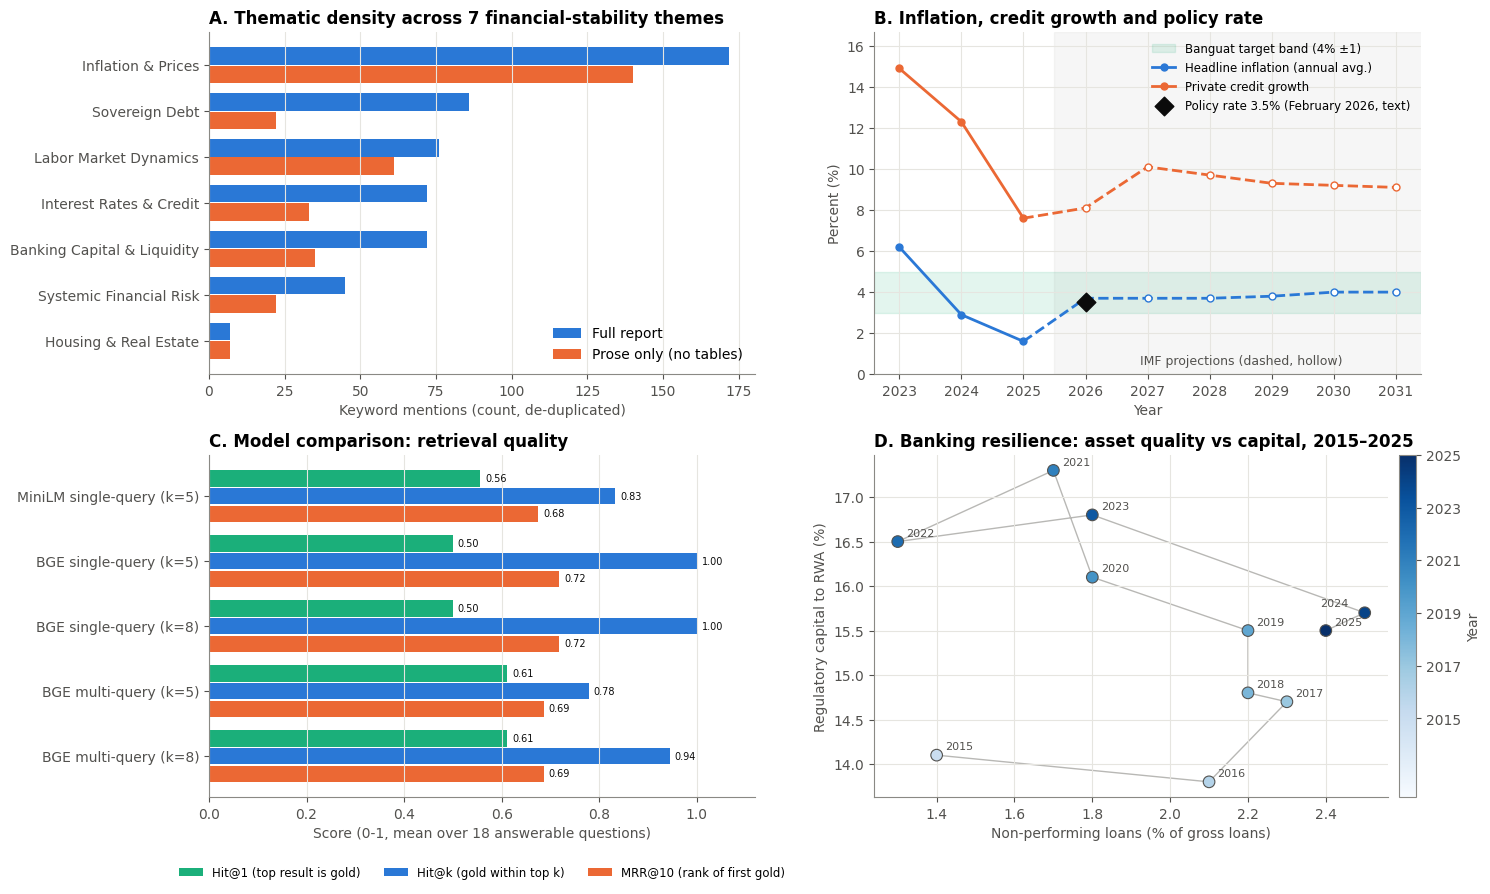

In [110]:
# test each panel on its own before composing the dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
plot_themes(axes[0, 0]); plot_inflation_rates(axes[0, 1])
plot_retrieval(axes[1, 0]); plot_banking(axes[1, 1], fig)
plt.tight_layout(); plt.show()

### 4.4 The dashboard (300 dpi)
The summary box at the top is not typed by hand. The first line comes from `indicators.json` (missing values show as "not reported"), and the second line is calculated from the time series and the evaluation results. So if the data changed, the box would change too.

In [111]:
def fmt(key, label):
    v = indicators[key]
    per = (raw_indicators.get(key) or {}).get("period")
    return f"{label}: not reported" if v == FALLBACK else f"{label}: {v:g}%" + (f" ({per})" if per else "")

kpi_line = "   |   ".join([fmt("gdp_growth_forecast_pct", "GDP growth (proj.)"),
                         fmt("headline_inflation_rate_pct", "Inflation"),
                         fmt("central_bank_policy_rate_pct", "Policy rate"),
                         fmt("non_performing_loan_ratio", "NPL ratio"),
                         fmt("unemployment_rate_pct", "Unemployment"),
                         fmt("tier_1_capital_ratio", "Tier 1 capital")])
print(kpi_line)

GDP growth (proj.): 3.8% (2026)   |   Inflation: 2.9% (May 2026)   |   Policy rate: 3.5% (February 2026)   |   NPL ratio: 2.4% (end-2025)   |   Unemployment: not reported   |   Tier 1 capital: not reported


In [112]:
infl_proj = wide.set_index("year").loc[REPORT_YEAR, S_INFL]
cap_s = wide.set_index("year")[S_CAP].dropna()
npl_s = wide.set_index("year")[S_NPL].dropna()
mq_gain = (rag_long.groupby("condition").completeness.mean()).round(2).to_dict()

insight_line = (f"Real policy rate ≈ {indicators['central_bank_policy_rate_pct'] - infl_proj:+.1f} pp vs projected "
                f"{REPORT_YEAR} inflation ({infl_proj:g}%)  •  Capital ratio {cap_s.iloc[-1]:g}% "
                f"(peak {cap_s.max():g}% in {cap_s.idxmax()}), NPLs {npl_s.iloc[-1]:g}% (low {npl_s.min():g}% in {npl_s.idxmin()})"
                f"  •  Multi-Query RAG completeness {mq_gain.get('multi')} vs {mq_gain.get('single')} (single)")
print(insight_line)

Real policy rate ≈ -0.2 pp vs projected 2026 inflation (3.7%)  •  Capital ratio 15.5% (peak 17.3% in 2021), NPLs 2.4% (low 1.3% in 2022)  •  Multi-Query RAG completeness 5.0 vs 4.0 (single)


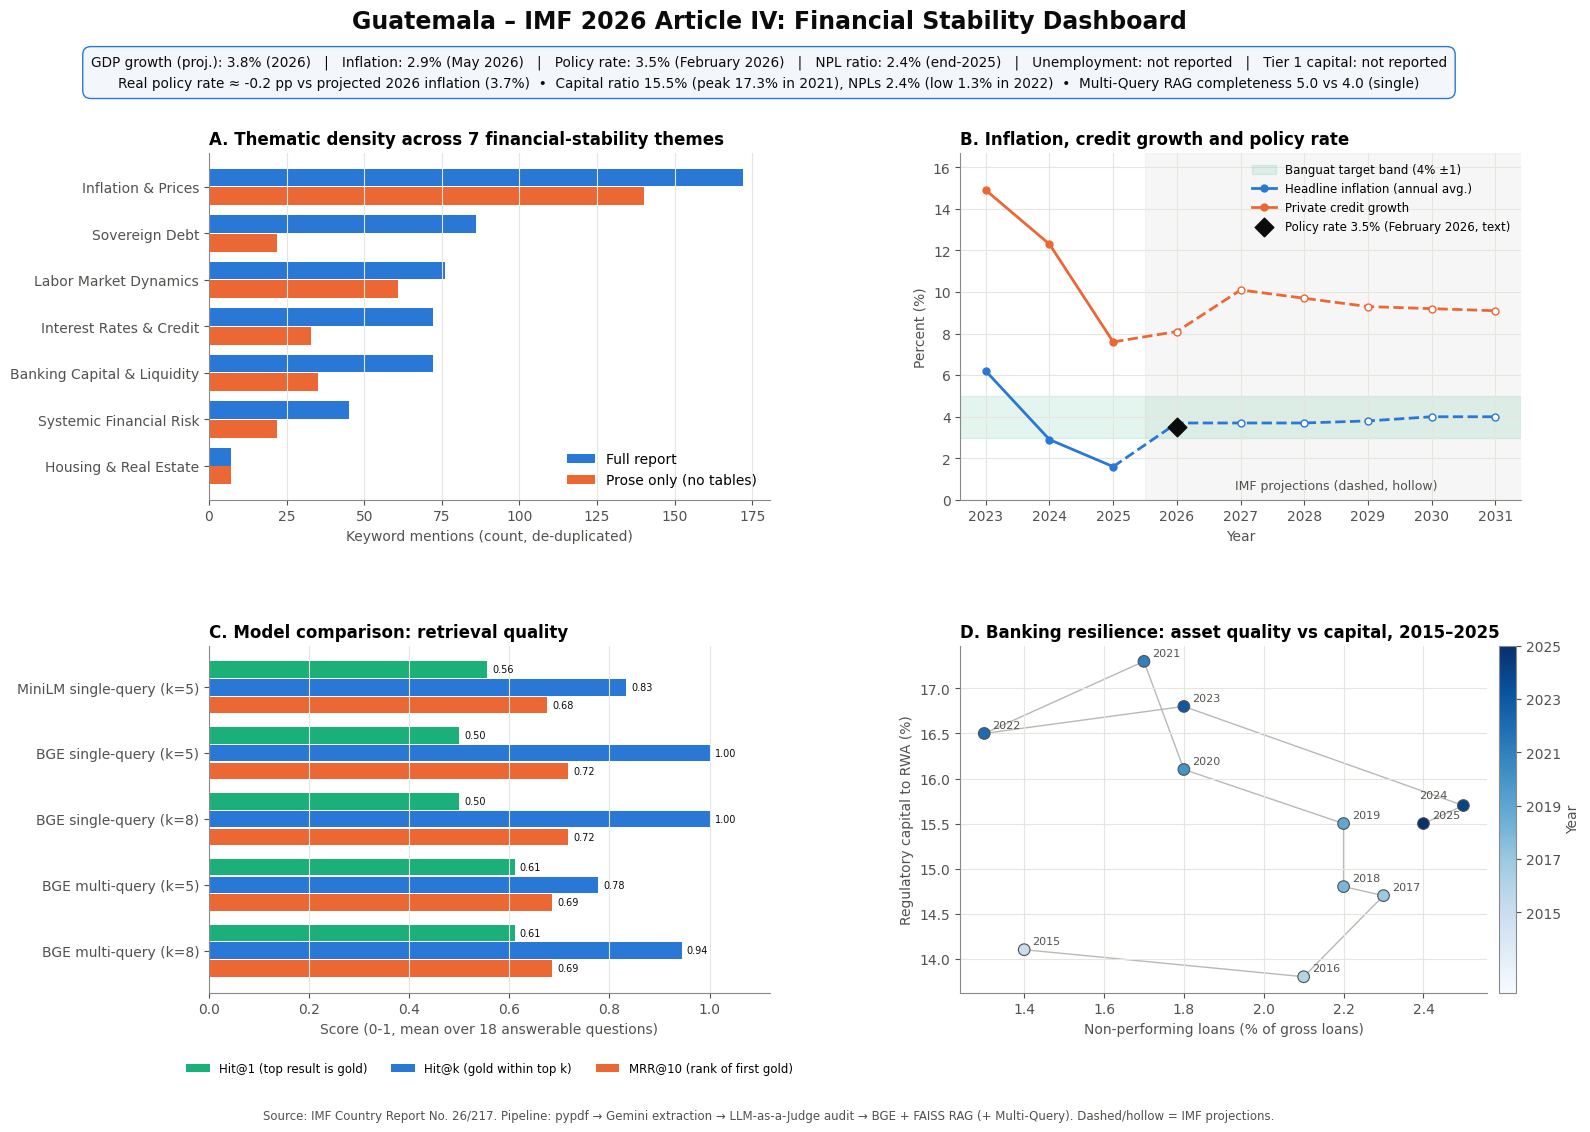

In [113]:
fig = plt.figure(figsize=(16, 11.5))
gs = fig.add_gridspec(2, 2, top=0.85, bottom=0.12, left=0.15, right=0.97, hspace=0.42, wspace=0.34)
plot_themes(fig.add_subplot(gs[0, 0]))
plot_inflation_rates(fig.add_subplot(gs[0, 1]))
plot_retrieval(fig.add_subplot(gs[1, 0]))
plot_banking(fig.add_subplot(gs[1, 1]), fig)

fig.text(0.5, 0.975, f"{COUNTRY} – IMF {REPORT_YEAR} Article IV: Financial Stability Dashboard",
         ha="center", va="top", fontsize=17, fontweight="bold", color=INK)
fig.text(0.5, 0.935, kpi_line + "\n" + insight_line, ha="center", va="top", fontsize=9.8, color=INK, linespacing=1.6,
         bbox=dict(boxstyle="round,pad=0.6", facecolor="#f3f6fb", edgecolor=BLUE, lw=1))
fig.text(0.5, 0.01, f"Source: IMF Country Report No. {REPORT_NO}. Pipeline: pypdf → Gemini extraction → "
         "LLM-as-a-Judge audit → BGE + FAISS RAG (+ Multi-Query). Dashed/hollow = IMF projections.",
         ha="center", fontsize=8.5, color=INK_SOFT)

DASHBOARD_PATH = os.path.join(FIG_DIR, "guatemala_dashboard.png")
fig.savefig(DASHBOARD_PATH, dpi=300, facecolor="white")
plt.show()

In [114]:
img = Image.open(DASHBOARD_PATH)
dpi = img.info.get("dpi", (0, 0))
assert round(dpi[0]) >= 300, "dashboard must be saved at >= 300 dpi"
print(f"{DASHBOARD_PATH}: {img.size[0]}x{img.size[1]} px at {round(dpi[0])} dpi")

/content/imf_outputs/figures/guatemala_dashboard.png: 4800x3450 px at 300 dpi


### 4.5 What the dashboard shows and what it means for policy
**A – What the IMF talks about most.** Inflation is the biggest theme (172 mentions, about a third). This is mostly because of the 2026 oil price shock and how much of it passes into prices (Box 1), not because inflation is high. Sovereign debt comes up 86 times in the full report but only 22 times in the written text, so most mentions are table labels. Debt is low (about 27% of GDP) and is treated as a strength, not a worry. Housing is almost missing (7 mentions), because real estate is not a big risk in Guatemala. **What it means:** the IMF's main concerns are handling price shocks and the government's ability to spend, not a financial bubble.

**B – Monetary policy.** Average inflation fell to 1.6% in 2025, below Banguat's 3–5% band, which explains the four rate cuts to 3.5%. The oil shock pushes projected 2026 inflation up to 3.7%, back inside the band, so the real interest rate is about zero or slightly negative (−0.2 points). Policy is still slightly supportive, and there is room to raise rates if prices keep rising. Credit growth halved from 14.9% in 2023 to 7.6% in 2025 and is projected to recover to about 9–10%. **What it means:** pausing the rate cuts makes sense. The bigger monetary issue is the large flow of remittance dollars, which Banguat has to absorb at a cost (GTQ 9.2 billion in 2025).

**C – Search models.** On the 18 test questions BGE found a gold chunk in the top 5 for every question (Hit@5 = 1.0), compared with 0.83 for MiniLM, and it had the higher MRR (0.72 vs 0.68). MiniLM was slightly better at getting the very first result right (Hit@1 0.56 vs 0.50). Multi-Query did not improve the search scores: Hit@5 fell to 0.83 and MRR to 0.68. But its *answers* were judged more complete (see the extension results). So better answers do not always come from better ranking.

**D – Bank health.** The capital ratio rose to a peak of 17.3% in 2021 and bad loans fell to a low of 1.3% in 2022. Since then both have moved the wrong way: capital is down to 15.5% and bad loans are up to 2.4%. I think this could be the fast credit growth of 2023–24 (14.9% and 12.3%) turning into weaker loans, but that is my own reading, not something the report says. The levels are still comfortable, and provisions cover about 131% of bad loans. **What it means:** it supports the IMF's push for expected-loss provisioning (fully in place by 2028), IFRS accounting and updating the 2002 banking law, so problems are dealt with before they turn into losses.

**Overall.** Guatemala has strong buffers: low debt, reserves of about twice the IMF's adequacy level, a current account surplus and inflation inside target. But it also has structural problems: tax revenue of only about 12% of GDP, slow spending on infrastructure (the infrastructure ministry spent only about 70% of its budget), informality of 75.9% and remittances of about 21% of GDP, which depend on US migration policy. The main policy message is to use the room in the budget for infrastructure while raising more tax, not to deal with a financial crisis.

### 4.6 Extra figure: judge scores
This figure shows the judge's scores for the summaries (Task 1) and for the RAG answers (normal search vs Multi-Query). The bar is the average, and the black tick is the **lowest** single score. Almost every average is at or near 5, so the lowest score is more informative than the average. The fact that nearly everything gets 5/5 also suggests a "lite" judge is not very good at telling good answers from very good ones.

In [115]:
def plot_judge(ax, df, group_col, colors, title):
    agg = df.groupby([group_col, "metric"]).score.agg(["mean", "min"]).reset_index()
    labels = agg[group_col] + " · " + agg["metric"].str.replace("_", " ")
    y = np.arange(len(agg))[::-1]
    ax.barh(y, agg["mean"], color=[colors[g] for g in agg[group_col]], height=0.55)
    ax.scatter(agg["min"], y, color=INK, marker="|", s=250, lw=2, zorder=5)
    for yi, m in zip(y, agg["mean"]):
        ax.text(m + 0.08, yi, f"{m:.2f}", va="center", fontsize=9)
    ax.set_yticks(y, labels); ax.set_xlim(0, 5.7)
    ax.set_xlabel("Judge score (1 = poor, 5 = excellent); tick = lowest single score")
    ax.set_title(title, loc="left"); ax.grid(axis="y", visible=False)

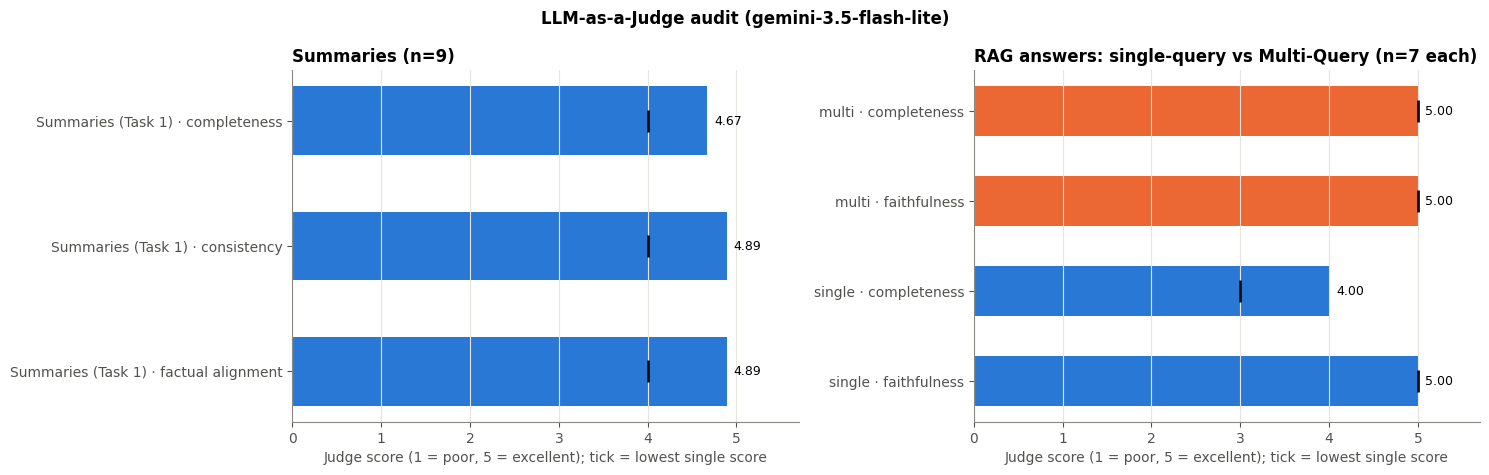

In [116]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.8))
plot_judge(a1, summ_long, "stage", {"Summaries (Task 1)": BLUE}, f"Summaries (n={len(judge_df)})")
plot_judge(a2, rag_scores, "condition", {"single": BLUE, "multi": ORANGE},
           f"RAG answers: single-query vs Multi-Query (n={len(EVAL_SET)} each)")
fig.suptitle(f"LLM-as-a-Judge audit ({', '.join(sorted(set(judge_df.judge_model)))})", fontweight="bold")
plt.tight_layout()
JUDGE_FIG_PATH = os.path.join(FIG_DIR, "judge_diagnostics.png")
fig.savefig(JUDGE_FIG_PATH, dpi=300, facecolor="white")
plt.show()

---
## Unit tests
These are small tests of the helper functions my checks depend on. Most of them come from problems I actually ran into, for example `28.0` vs `28`, citations written as `[chunks 12, 23]`, JSON wrapped in code fences, and the NPL sentence broken after a dash. They don't use the API.

In [117]:
# number matching
assert re.search(num_regex("28"), "debt 28.0 percent") and not re.search(num_regex("27"), "debt 27.2")
assert not re.search(num_regex("2.4"), "12.4") and re.search(num_regex("-1.9"), "balance -1.9")
assert check_numbers("Growth was 4.3 percent in 2025.", "at 4.3 percent")["support_rate"] == 1.0
assert check_numbers("Growth was 5.1 percent.", "at 4.3 percent")["unsupported_numbers"] == ["5.1"]
# JSON parsing
assert parse_json('```json\n{"a": 1}\n```') == {"a": 1}
assert parse_json('Here you go: [1, 2]') == [1, 2]
assert to_float("3.8%") == 3.8 and to_float(None) is None and to_float("n/a") is None
print("number + JSON tests passed")

number + JSON tests passed


In [118]:
# citations and answer status
assert cited_ids("See [chunk 12] and [chunks 3, 4].") == {12, 3, 4}
assert cited_ids("[chunk 118, chunk 38]") == {118, 38}
assert answer_status({"answer": "X [chunk 9]", "unit_ids": [1, 2]}) == "citation error [9]"
assert answer_status({"answer": REFUSAL, "unit_ids": [1]}) == "refused"
# quote matching ignores line breaks / dashes; schema validation rejects wrong types
# the real NPL sentence is split by a line break after an em dash in the cleaned text - it must still match
assert quote_support("NPLs—concentrated in consumer, microcredit, and mortgage portfolios—stood at 2.4 percent at end-2025") >= 0.8
bad = {**indicators, "tier_1_capital_ratio": "n/a"}
try:
    validate_schema(bad); raise AssertionError("schema accepted a string")
except AssertionError as e:
    assert "must be float" in str(e)
print("citation + quote + schema tests passed")

citation + quote + schema tests passed


In [119]:
# chunking: every chunk within budget, and overlap is made of whole units from the previous chunk
assert all(c["n_tokens"] <= CHUNK_TOKENS + CHUNK_OVERLAP + 10 for c in chunks)
starts_with_overlap = sum(chunks[i]["text"][:40] in chunks[i - 1]["text"] for i in range(1, len(chunks)))
print(f"chunks starting with text from the previous chunk (overlap): {starts_with_overlap}/{len(chunks) - 1}")
assert "".join(sections.values()) == full_text
print("chunking + coverage tests passed")

chunks starting with text from the previous chunk (overlap): 146/150
chunking + coverage tests passed


## Reproducibility record
This cell prints the library versions, when the run finished, and how many answers came from the cache. In my final run, 45 answers came from the cache and only 3 needed new API calls. On a second *Run all* it would be 0.

In [120]:
import platform, importlib.metadata as im
def version_of(pkg):
    try:
        return im.version(pkg)
    except im.PackageNotFoundError:
        return "not found"

versions = {p: version_of(p) for p in ["pypdf", "tiktoken", "google-genai", "sentence-transformers", "faiss-cpu",
                                        "pandas", "matplotlib", "numpy"]}
print("Python", platform.python_version(), "|", versions)
print("LLM answers this run:", dict(CALL_STATS))
print("Run finished:", time.strftime("%Y-%m-%d %H:%M"))

Python 3.13.18 | {'pypdf': '6.21.4', 'tiktoken': '0.14.0', 'google-genai': '2.12.1', 'sentence-transformers': '5.7.0', 'faiss-cpu': '1.15.1', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'numpy': '2.4.6'}
LLM answers this run: {'api calls': 47}
Run finished: 2026-11-06 21:21


---
## Key findings (calculated)
Every number I use in my report comes from this cell, so the report and the notebook always agree.

In [121]:
models_used = Counter(v["model"] for v in llm_cache.values())
findings = {
    "report": f"IMF Country Report No. {REPORT_NO}",
    "cleaning_pct_removed": round(100 - 100 * len(full_text) / raw_chars, 1),
    "chunks": len(chunks), "retrieval_units": len(rag_units),
    "summary_words_max": max(r["words"] for r in section_results.values()),
    "judge_means": judge_df[SCORE_COLS].mean().round(2).to_dict(),
    "numeric_support_exec_summary": grounding["EXECUTIVE SUMMARY"]["support_rate"],
    "indicators": indicators, "fallbacks": list(fallback_log),
    "trend_series_verified": int(trend_check_df.values_found.sum()), "trend_series": len(trends),
    "minilm_text_unseen_pct": float(trunc_df.loc["MiniLM", "text_unseen_pct"]),
    "cleaning_kept_text_identical_pages": f"{sum(identical)}/{len(pages)}",
    "retrieval_questions": len(ANSWERABLE),
    "citation_repairs": {c: [q for q, r in rs.items() if r.get("repaired")] for c, rs in rag_results.items()},
    "llm_calls_this_run": dict(CALL_STATS),
    "retrieval": retrieval_df.to_dict("records"),
    "rag_means": rag_long.groupby("condition")[["faithfulness", "completeness"]].mean().round(2).to_dict("index"),
    "rag_status": rag_long.groupby(["condition", "status"]).size().to_dict(),
    "models_used": dict(models_used),
}
save_json({k: (str(v) if isinstance(v, dict) and any(isinstance(x, tuple) for x in v) else v)
           for k, v in findings.items()}, os.path.join(OUT_DIR, "findings.json"))
for k, v in findings.items():
    print(f"{k}: {v}")

report: IMF Country Report No. 26/217
cleaning_pct_removed: 4.1
chunks: 151
retrieval_units: 151
summary_words_max: 94
judge_means: {'consistency': 4.89, 'completeness': 4.67, 'factual_alignment': 4.89}
numeric_support_exec_summary: 1.0
indicators: {'country_name': 'Guatemala', 'gdp_growth_forecast_pct': 3.8, 'headline_inflation_rate_pct': 2.9, 'central_bank_policy_rate_pct': 3.5, 'non_performing_loan_ratio': 2.4, 'unemployment_rate_pct': -1.0, 'tier_1_capital_ratio': -1.0}
fallbacks: ['unemployment_rate_pct', 'tier_1_capital_ratio']
trend_series_verified: 9
trend_series: 9
minilm_text_unseen_pct: 20.0
cleaning_kept_text_identical_pages: 78/78
retrieval_questions: 18
citation_repairs: {'single': [], 'multi': []}
llm_calls_this_run: {'api calls': 47}
retrieval: [{'config': 'MiniLM single-query', 'hit@1': 0.556, 'hit@k': 0.833, 'mrr@10': 0.675, 'k': 5, 'n': 18}, {'config': 'BGE single-query', 'hit@1': 0.5, 'hit@k': 1.0, 'mrr@10': 0.718, 'k': 5, 'n': 18}, {'config': 'BGE single-query', 'h

In [122]:
print("Files in", OUT_DIR)
for root, _, files in os.walk(OUT_DIR):
    for f in sorted(files):
        if not f.endswith(".tmp"):
            p = os.path.join(root, f)
            print(f"  {os.path.relpath(p, OUT_DIR):45s} {os.path.getsize(p) / 1024:8.1f} KB")

Files in /content/imf_outputs
  chunks.json                                      222.3 KB
  cleaned_text.txt                                 182.1 KB
  findings.json                                      2.0 KB
  indicators.json                                    0.2 KB
  sections.json                                    184.3 KB
  task1_summaries.json                              24.5 KB
  task2_outputs.json                                20.7 KB
  task3_rag.json                                   179.0 KB
  task4_long_format.json                             9.0 KB
  figures/guatemala_dashboard.png                  906.9 KB
  figures/judge_diagnostics.png                    210.7 KB
  cache/emb_BGE_de21f91431d387f1.npy               226.6 KB
  cache/emb_MiniLM_176e5eff08e0350f.npy            226.6 KB
  cache/faiss_BGE_de21f91431d387f1.index           226.5 KB
  cache/faiss_MiniLM_176e5eff08e0350f.index        226.5 KB
  cache/llm_cache.json                              55.5 KB


## Discussion

### How I built the pipeline and why
I split the report into chunks of about 350 tokens and carried the last full sentences of each chunk into the next one, so chunks end up at up to about 400 tokens. I did it this way because my first version cut the text every 400 tokens, and chunks often started in the middle of a word. Keeping whole sentences means a fact is never cut in half. For the summaries I first made short notes for each section and then combined them, because the report is about 46,000 tokens and the tables would have been lost if I summarised it in one go. I also asked the model to return JSON and then checked it in Python, so the outputs could be tested and plotted instead of just read.

### Problems I found and how I fixed them
Most of my improvements came from things going wrong:
- **Truncation.** MiniLM only reads the first 256 tokens of a chunk. In my first version this meant it never saw about a third of the report, and it missed an answer that was in the text. I measured this and switched to BGE, which reads 512 tokens. With my final chunks MiniLM still misses 20% of the text, and BGE misses none.
- **Cleaning.** My first cleaning step joined words split across lines, which turned "near-term" into "nearterm". I checked the PDF and all 25 cases were real hyphenated words, so now I keep the hyphen. I also added a check that proves cleaning only removes whole lines: the kept text was unchanged on all 78 pages.
- **Projection years.** The model marked 2025 as a projection for every series, because PDF extraction loses the table headers. I fixed it with a rule based on the report year, which the report's own wording supports.
- **A made-up citation.** In the final run, one Multi-Query answer cited chunk 57, which it had never been given. My citation check caught it, and the automatic retry produced a correct answer. Both versions are saved.
- **My own checker.** My first validator marked 5 correct time series as wrong because it wrote 28.0 as 28. Later it said the NPL quote was not in the report, because the PDF breaks that sentence after a dash. Both times the model was right and my code was wrong, so I added unit tests for the checking functions.

### Why the models gave different results
**MiniLM vs BGE.** BGE can read twice as much text and was trained specifically for search, matching questions to passages, while MiniLM was trained for general sentence similarity. On my first 7 questions every model found the answer, and MiniLM even had the higher MRR (0.92 vs 0.75), so that test could not show any difference. With the 18 harder questions the difference appeared: BGE found a gold chunk in the top 5 for every question (Hit@5 = 1.0 vs 0.83 for MiniLM) and had the higher MRR (0.72 vs 0.68). MiniLM was slightly better at the very first result (Hit@1 0.56 vs 0.50). My explanation is that MiniLM works fine when the answer is near the start of a chunk, but misses it completely when the answer is in the part it cannot read. So BGE is more reliable, even if it is not always sharper at the top.

**Multi-Query vs single query.** Multi-Query answers were judged more complete (4.67 vs 4.17 out of 5), but its search scores were not better: Hit@5 fell from 1.0 to 0.83 and MRR from 0.72 to 0.68. I think the extra phrasings pull in chunks on related topics. That gives the answer model a wider picture but sometimes pushes the single best chunk down the list. More context also has costs: the only made-up citation was in the Multi-Query version with 8 chunks, and on the inflation question Multi-Query scored lower for completeness (3 vs 5). So more context helped on average, but not every time.

**Different extractor models.** Because of the free-tier limits, the notebook had to switch between several Gemini Flash models. I recorded which model produced each output, so it is clear where results might not be directly comparable.

### Can the judge be trusted?
Not on its own. Almost every score was 5 out of 5 (averages of 4.78–4.89 for the summaries), so the judge does not really separate good answers from very good ones. I also noticed four problems:
1. It sometimes ignored the verdict labels I asked it to use.
2. When I gave it the extractor's reasons, it copied them instead of checking for itself, so I removed them from the prompt.
3. At first it judged completeness only against the chunks that were retrieved, not against everything available.
4. It gave the Tier 1 trap question 1 out of 5 for completeness, even though refusing was the correct answer. I now leave that question out of completeness and check instead that it was refused correctly (it was, in both methods).

The judge was useful in one case: it spotted that the Outlook summary linked expected-loss provisioning to "financial stability", which a number check could never catch. So I used the judge together with checks that give the same result every time: all 64 summary numbers were found in the source, all 10 time series matched their table rows, and every indicator quote was found in the report.

### What the results say about Guatemala
Overall, Guatemala looks financially stable but has deeper structural problems. Average inflation fell to 1.6% in 2025, below Banguat's 4% ± 1 band, and the oil shock is expected to bring it back to 3.7% in 2026. The policy rate (3.5%) is slightly below that, so monetary policy is still mildly supportive after four rate cuts. Public debt is low at about 27% of GDP, and reserves are about twice the IMF's adequacy level, which gives the country room to deal with shocks.

The banks are well capitalised, but since 2021 the capital ratio has fallen from 17.3% to 15.5% and bad loans (NPLs) have risen from a low of 1.3% to 2.4%. I think this could be linked to the fast credit growth in 2023 and 2024 (14.9% and 12.3%) turning into weaker loans. That is my own interpretation, not something the report says, and it is worth watching rather than worrying about, because provisions still cover about 131% of bad loans.

The bigger problems are structural. Tax revenue is only about 12% of GDP, which limits spending on infrastructure, and even the money in the budget is not fully spent (the infrastructure ministry spent only about 70%). About three-quarters of workers are informal (75.9%), which is also why the report gives no unemployment rate. Remittances are about 21% of GDP, so changes to US migration policy could hit the economy hard, and El Niño adds climate risk on top of that.

### Limitations
Seven judged questions and an 18-question retrieval test are enough to show differences between the methods, but not enough to prove them statistically. My gold answers are text patterns, so a chunk could answer a question in different words and still be counted as a miss. Some outputs come from different Gemini models because of the quota limits. Finally, all of this is based on one report about one country, so the results may not apply to other reports.